# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.trees import xfastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/first_batch'

## Pick the hourly or 5-min granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity
- WFV, train+=28 (train set increasing), validation=28, 5-min granularity

## Evaluation Settings

In [4]:
DATA_FREQUENCY = 'H' # '15min'
USE_RESIDUAL = True  # If True, model the residuals (1-step differencing) instead of the original target.
FORECAST_HORIZON = '1h'
SPIKE_PROMINENCE = 10

In [5]:
# Measure loading time
start_time = time.time()

# Load data

train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_1h_wfv', use_numpy=True)
ALL_FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
                'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
                'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
                'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
                'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
                'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
                'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
                'L3_act_power_lag_1h', 'L3_act_power_lag_24h', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
                'L3_current_lag_1h', 'L3_current_lag_24h', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
                'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
                'grid_freq_lag_1h', 'grid_freq_lag_24h', 
                'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
                'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
                'powerfactor3_lag_1h', 'powerfactor3_lag_24h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 6 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 6 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.00 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 6 splits
Validation data: 6 splits
First train split shape: X=(554, 43), y=(554,)
First valid split shape: X=(573, 43), y=(573,)

Memory usage:
Train: 4.01 MB
Valid: 1.16 MB
Test: 0.73 MB
Total: 5.89 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (seasonal averages)

In [7]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [8]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00

Time: 0.01 seconds
Predicting for chunk from 2022-10-22 13:00:00 to 2022-11-05 13:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2022-11-05 13:00:00

Time: 0.00 seconds
Predicting for chunk from 2022-11-05 14:00:00 to 2022-11-15 09:00:00

-------------------------
Model's memory usage: 0.024162 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2631
	MAE: 0.1573
	MAPE: 19.9237%

Directional Metrics:
	Directional Accuracy: 43.3566%
	First-Diff Correlation: -0.1062

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spi

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00

Time: 0.00 seconds
Predicting for chunk from 2022-11-15 10:00:00 to 2022-11-29 10:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2022-11-29 10:00:00

Time: 0.00 seconds
Predicting for chunk from 2022-11-29 11:00:00 to 2022-12-09 07:00:00

-------------------------
Model's memory usage: 0.024048 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2285
	MAE: 0.1480
	MAPE: 26.8072%

Directional Metrics:
	Directional Accuracy: 42.2339%
	First-Diff Correlation: 0.2325

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2023-02-16 11:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-02-16 12:00:00 to 2023-03-02 12:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-03-02 12:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-03-02 13:00:00 to 2023-03-12 08:00:00

-------------------------
Model's memory usage: 0.024048 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-16 12:00:00 - 2023-03-12 08:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1924
	MAE: 0.1261
	MAPE: 35.4715%

Directional Metrics:
	Directional Accuracy: 36.3636%
	First-Diff Correlation: 0.1609

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1111
		F1: 0.1250
	Drops:
		Precision: 0.0714
		Recall: 0.0556
		F1: 0.0625

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-03-12 09:00:00 to 2023-03-26 09:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-03-26 09:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-03-26 10:00:00 to 2023-04-05 06:00:00

-------------------------
Model's memory usage: 0.024048 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2087
	MAE: 0.1312
	MAPE: 30.4092%

Directional Metrics:
	Directional Accuracy: 41.0122%
	First-Diff Correlation: 0.1794

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3571
		Recall: 0.2941
		F1: 0.3226
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

#### Results

In [9]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2163 ± 0.0271
	MAE: 0.1363 ± 0.0125
	MAPE: 29.3355% ± 5.1199%

	Directional Metrics:
		Directional Accuracy: 40.6408% ± 2.7523%
		First-Diff Correlation: 0.1799 ± 0.1460

	Immediate Detection (delta=0):
		Spike Precision: 0.0962 ± 0.1281
		Spike Recall: 0.0804 ± 0.1049
		Spike F1: 0.0874 ± 0.1153
		Drop Precision: 0.0342 ± 0.0344
		Drop Recall: 0.0310 ± 0.0313
		Drop F1: 0.0324 ± 0.0326

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.7463 ± 0.3546
		Spike Recall: 0.5822 ± 0.3055
		Spike F1: 0.6418 ± 0.3143
		Drop Precision: 0.2808 ± 0.1605
		Drop Recall: 0.2401 ± 0.1681
		Drop F1: 0.2560 ± 0.1661
Daily Metrics:
	RMSE: 0.2123 ± 0.1126
	MAE: 0.1270 ± 0.0422
	MAPE: 1.4093% ± 0.8976%

	Directional Metrics:
		Directional Accuracy: 96.1574% ± 2.5124%
		First-Diff Correlation: 0.9991 ± 0.0012

	Immediate Detection (delta=0):


#### Validation plots

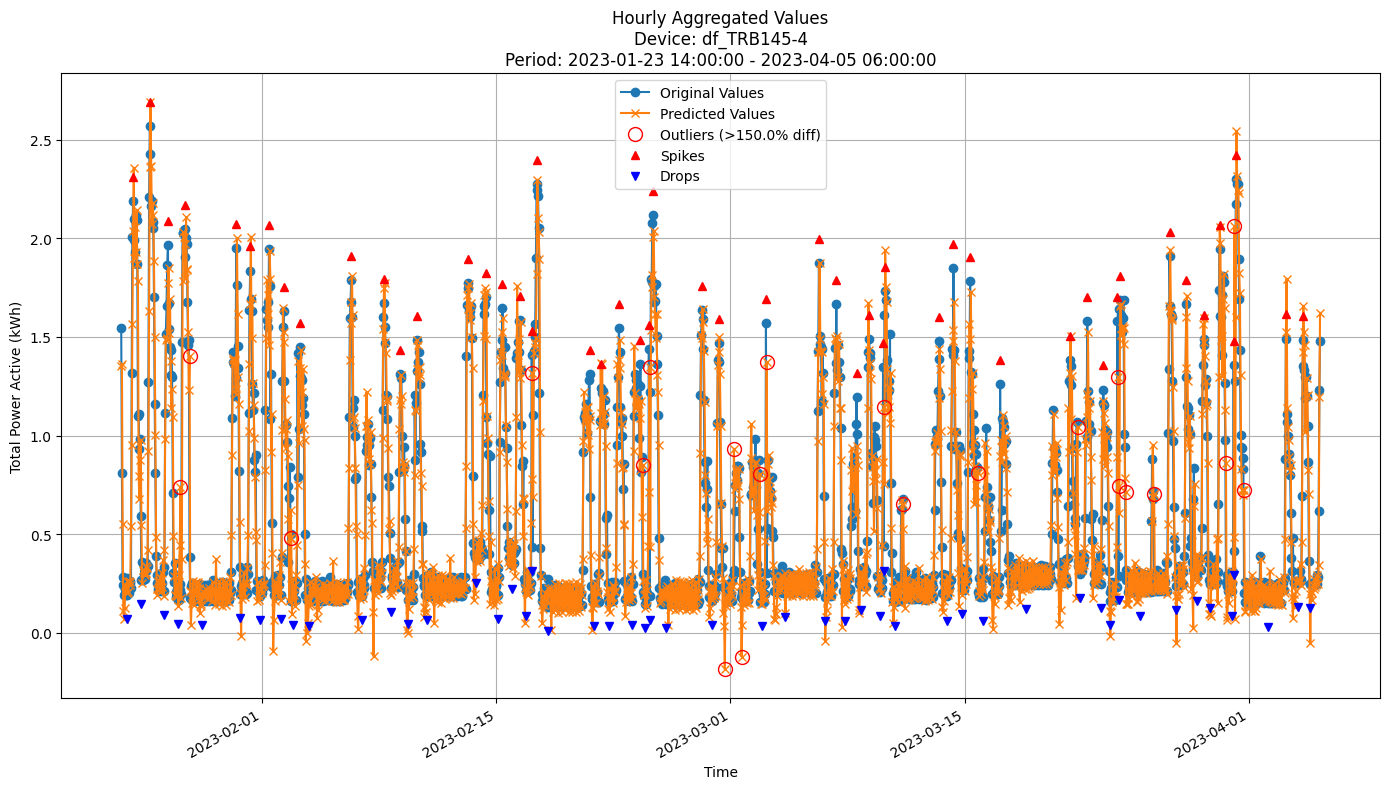


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1939
MAE: 0.1263
MAPE: 31.6980%

Directional Metrics:
Directional Accuracy: 38.3721%
First-Diff Correlation: 0.2401

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1591
  Recall: 0.1373
  F1 Score: 0.1474
Drops:
  Precision: 0.0444
  Recall: 0.0385
  F1 Score: 0.0412

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9091
  Recall: 0.7843
  F1 Score: 0.8421
Drops:
  Precision: 0.3333
  Recall: 0.2885
  F1 Score: 0.3093


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [11]:
update_freq = "1H"
bl_prev = PreviousValueRegressor
bl_prev_params = {'is_residual': True}

In [12]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00
Model's memory usage: 0.000320 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2600
	MAE: 0.1511
	MAPE: 17.9629%

Directional Metrics:
	Directional Accuracy: 33.0420%
	First-Diff Correlation: -0.0603

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00
Model's memory usage: 0.000320 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2667
	MAE: 0.1528
	MAPE: 24.0071%

Directional Metrics:
	Directional Accuracy: 37.8709%
	First-Diff Correlation: 0.2342

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
----

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-02-16 11:00:00
Model's memory usage: 0.000320 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-16 12:00:00 - 2023-03-12 08:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2506
	MAE: 0.1422
	MAPE: 35.5897%

Directional Metrics:
	Directional Accuracy: 34.9650%
	First-Diff Correlation: -0.1239

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00
Model's memory usage: 0.000320 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2371
	MAE: 0.1401
	MAPE: 29.4535%

Directional Metrics:
	Directional Accuracy: 36.9983%
	First-Diff Correlation: 0.0275

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
----

#### Results

In [13]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2552 ± 0.0117
	MAE: 0.1464 ± 0.0045
	MAPE: 28.2891% ± 5.7947%

	Directional Metrics:
		Directional Accuracy: 35.8068% ± 1.5436%
		First-Diff Correlation: 0.0808 ± 0.1412

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8333 ± 0.3727
		Spike Recall: 0.8333 ± 0.3727
		Spike F1: 0.8333 ± 0.3727
		Drop Precision: 0.8333 ± 0.3727
		Drop Recall: 0.8333 ± 0.3727
		Drop F1: 0.8333 ± 0.3727
Daily Metrics:
	RMSE: 0.3626 ± 0.1057
	MAE: 0.1454 ± 0.0379
	MAPE: 1.8582% ± 0.7830%

	Directional Metrics:
		Directional Accuracy: 94.7685% ± 3.3272%
		First-Diff Correlation: 0.9987 ± 0.0014

	Immediate Detection (delta=0):


#### Validation plots

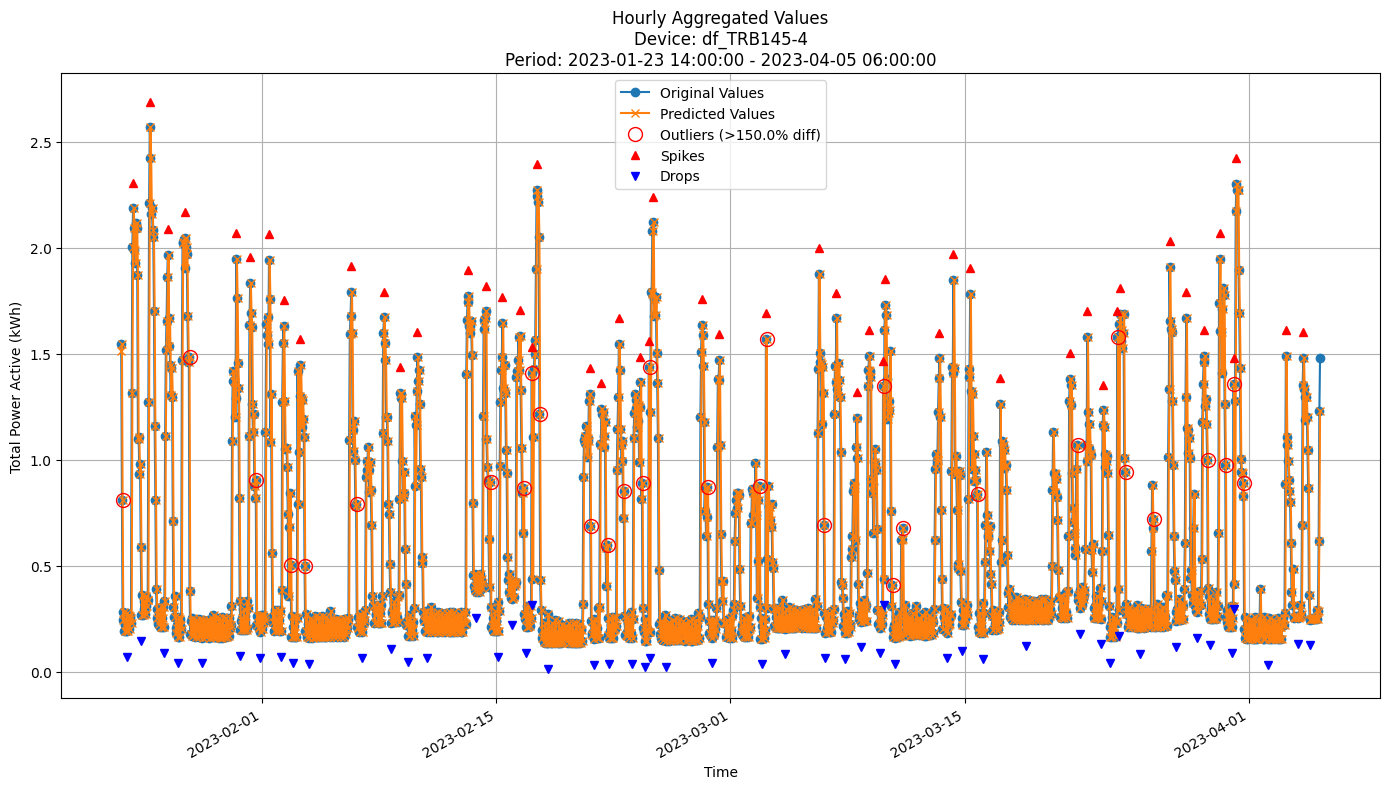


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2447
MAE: 0.1426
MAPE: 31.7252%

Directional Metrics:
Directional Accuracy: 36.1628%
First-Diff Correlation: 0.0433

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [14]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [15]:
update_freq = "14D"  # Update the model every 14 days

gbdt = GradientBoostingRegressor
gbdt_params = dict(n_estimators=100, learning_rate=0.03, subsample=0.8, max_depth=10, random_state=42)

In [16]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt, 
    model_params=gbdt_params, 
    train=train, 
    valid=valid, 
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00

Time: 1.74 seconds
Predicting for chunk from 2022-10-22 13:00:00 to 2022-11-05 13:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2022-11-05 13:00:00

Time: 2.81 seconds
Predicting for chunk from 2022-11-05 14:00:00 to 2022-11-15 09:00:00

-------------------------
Model's memory usage: 0.009666 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2678
	MAE: 0.1811
	MAPE: 26.0030%

Directional Metrics:
	Directional Accuracy: 39.3357%
	First-Diff Correlation: 0.0271

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00

Time: 4.92 seconds
Predicting for chunk from 2022-11-15 10:00:00 to 2022-11-29 10:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2022-11-29 10:00:00

Time: 6.34 seconds
Predicting for chunk from 2022-11-29 11:00:00 to 2022-12-09 07:00:00

-------------------------
Model's memory usage: 0.009666 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2378
	MAE: 0.1564
	MAPE: 29.2588%

Directional Metrics:
	Directional Accuracy: 43.9791%
	First-Diff Correlation: 0.3145

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2023-02-16 11:00:00

Time: 13.10 seconds
Predicting for chunk from 2023-02-16 12:00:00 to 2023-03-02 12:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-03-02 12:00:00

Time: 13.26 seconds
Predicting for chunk from 2023-03-02 13:00:00 to 2023-03-12 08:00:00

-------------------------
Model's memory usage: 0.009666 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-16 12:00:00 - 2023-03-12 08:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2365
	MAE: 0.1295
	MAPE: 34.0306%

Directional Metrics:
	Directional Accuracy: 41.0839%
	First-Diff Correlation: 0.0506

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0667
		Recall: 0.0556
		F1: 0.0606
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Sp

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00

Time: 11.98 seconds
Predicting for chunk from 2023-03-12 09:00:00 to 2023-03-26 09:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-03-26 09:00:00

Time: 12.57 seconds
Predicting for chunk from 2023-03-26 10:00:00 to 2023-04-05 06:00:00

-------------------------
Model's memory usage: 0.009666 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2039
	MAE: 0.1310
	MAPE: 29.4077%

Directional Metrics:
	Directional Accuracy: 35.4276%
	First-Diff Correlation: 0.1401

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3571
		Recall: 0.2941
		F1: 0.3226
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Sp

#### Results

In [17]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0492 ± 0.0119
	MAE: 0.0375 ± 0.0079
	MAPE: 8.5826% ± 1.9516%

	Directional Metrics:
		Directional Accuracy: 71.4221% ± 8.2601%
		First-Diff Correlation: 0.9489 ± 0.0229

	Immediate Detection (delta=0):
		Spike Precision: 0.4259 ± 0.4371
		Spike Recall: 0.3556 ± 0.3843
		Spike F1: 0.3830 ± 0.4006
		Drop Precision: 0.0584 ± 0.0632
		Drop Recall: 0.0468 ± 0.0518
		Drop F1: 0.0513 ± 0.0559

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4877 ± 0.4883
		Spike Recall: 0.4056 ± 0.4218
		Spike F1: 0.4379 ± 0.4438
		Drop Precision: 0.0856 ± 0.1005
		Drop Recall: 0.0644 ± 0.0711
		Drop F1: 0.0725 ± 0.0813
Daily Metrics:
	RMSE: 0.1133 ± 0.0374
	MAE: 0.0818 ± 0.0282
	MAPE: 0.6890% ± 0.2928%

	Directional Metrics:
		Directional Accuracy: 95.8238% ± 1.8810%
		First-Diff Correlation: 0.9998 ± 0.0001

	Immediate Detection (delta=0):
	

#### Training plots

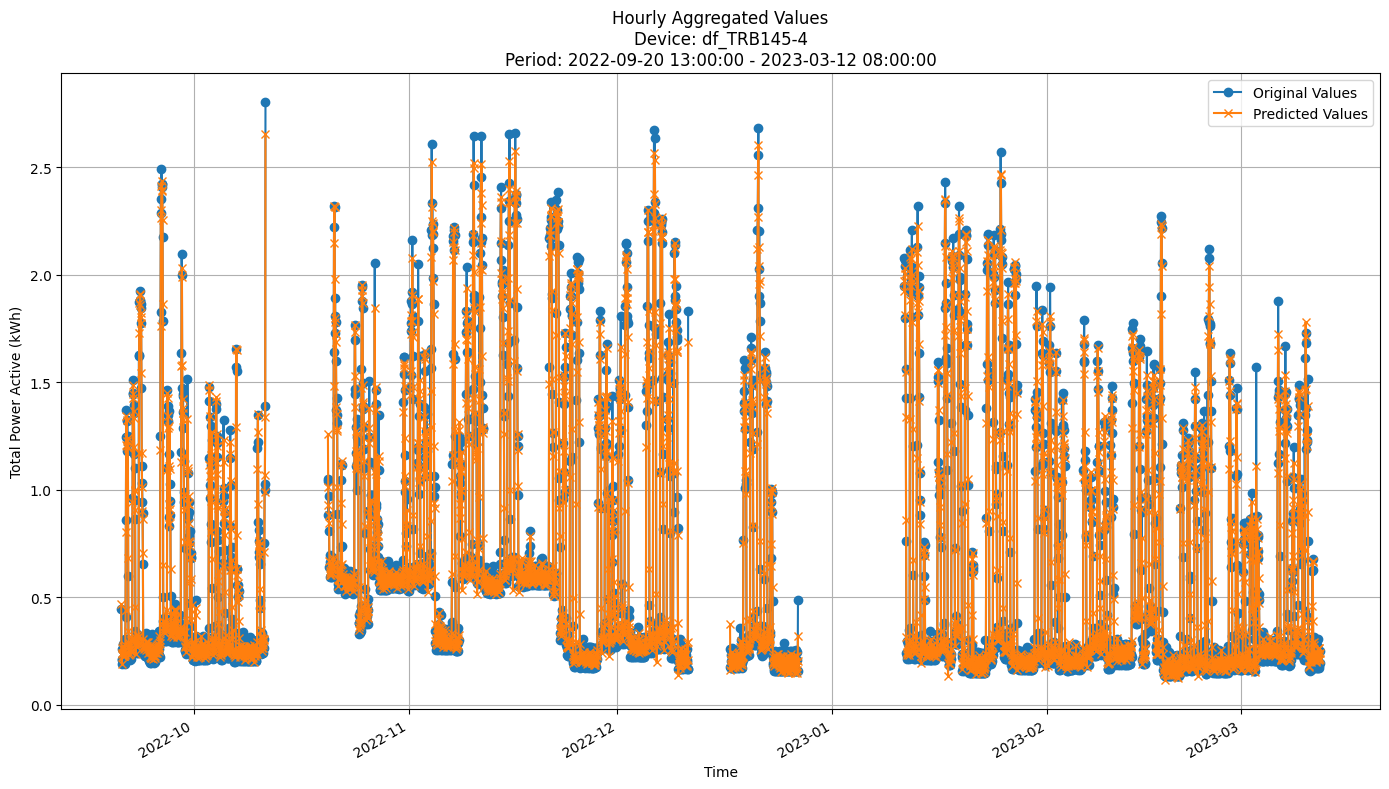


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0633
MAE: 0.0467
MAPE: 11.3353%

Directional Metrics:
Directional Accuracy: 62.7376%
First-Diff Correlation: 0.9187

Immediate Detection (delta=0):
Spikes:
  Precision: 0.6667
  Recall: 0.6000
  F1 Score: 0.6316
Drops:
  Precision: 0.1538
  Recall: 0.1379
  F1 Score: 0.1455

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9259
  Recall: 0.8333
  F1 Score: 0.8772
Drops:
  Precision: 0.1923
  Recall: 0.1724
  F1 Score: 0.1818


In [18]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

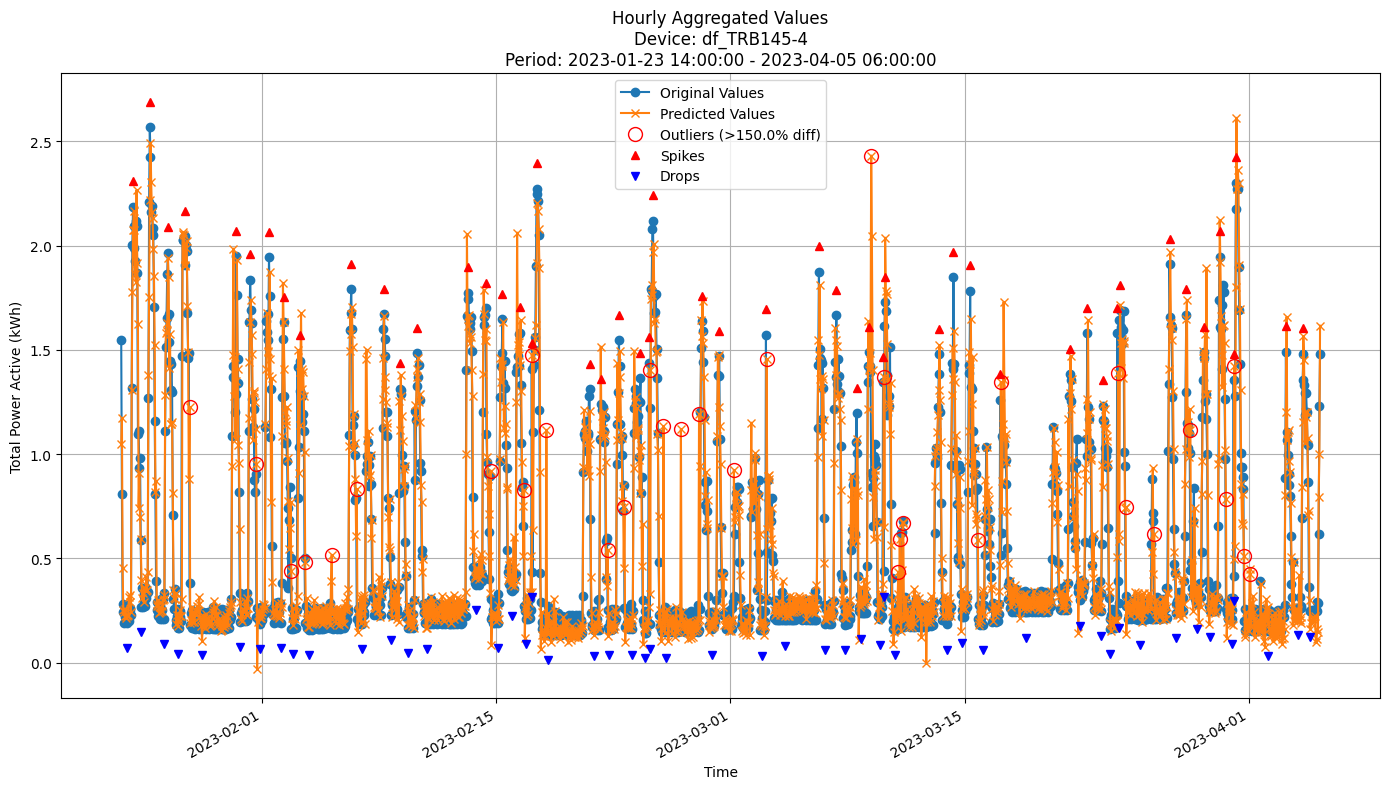


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2092
MAE: 0.1241
MAPE: 29.6972%

Directional Metrics:
Directional Accuracy: 40.0581%
First-Diff Correlation: 0.2044

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1818
  Recall: 0.1569
  F1 Score: 0.1684
Drops:
  Precision: 0.0455
  Recall: 0.0385
  F1 Score: 0.0417

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7273
  Recall: 0.6275
  F1 Score: 0.6737
Drops:
  Precision: 0.2045
  Recall: 0.1731
  F1 Score: 0.1875


In [19]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# Basic Prediction Metrics:
# RMSE: 0.2195
# MAE: 0.1398
# MAPE: 33.6987%

### Random Forest model

In [20]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = dict(n_estimators=100, max_depth=10, max_features='sqrt', random_state=42, n_jobs=-1)

In [21]:

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00

Time: 0.19 seconds
Predicting for chunk from 2022-10-22 13:00:00 to 2022-11-05 13:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2022-11-05 13:00:00

Time: 0.19 seconds
Predicting for chunk from 2022-11-05 14:00:00 to 2022-11-15 09:00:00

-------------------------
Model's memory usage: 0.043777 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2315
	MAE: 0.1435
	MAPE: 18.9269%

Directional Metrics:
	Directional Accuracy: 33.2168%
	First-Diff Correlation: 0.0300

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0769
		Recall: 0.0714
		F1: 0.0741
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00

Time: 0.22 seconds
Predicting for chunk from 2022-11-15 10:00:00 to 2022-11-29 10:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2022-11-29 10:00:00

Time: 0.22 seconds
Predicting for chunk from 2022-11-29 11:00:00 to 2022-12-09 07:00:00

-------------------------
Model's memory usage: 0.043777 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2169
	MAE: 0.1395
	MAPE: 25.8141%

Directional Metrics:
	Directional Accuracy: 37.6963%
	First-Diff Correlation: 0.3449

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2023-02-16 11:00:00

Time: 0.44 seconds
Predicting for chunk from 2023-02-16 12:00:00 to 2023-03-02 12:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-03-02 12:00:00

Time: 0.51 seconds
Predicting for chunk from 2023-03-02 13:00:00 to 2023-03-12 08:00:00

-------------------------
Model's memory usage: 0.043777 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-16 12:00:00 - 2023-03-12 08:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2143
	MAE: 0.1227
	MAPE: 31.9924%

Directional Metrics:
	Directional Accuracy: 35.3147%
	First-Diff Correlation: 0.0462

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0667
		Recall: 0.0556
		F1: 0.0606
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00

Time: 0.57 seconds
Predicting for chunk from 2023-03-12 09:00:00 to 2023-03-26 09:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-03-26 09:00:00

Time: 0.62 seconds
Predicting for chunk from 2023-03-26 10:00:00 to 2023-04-05 06:00:00

-------------------------
Model's memory usage: 0.043777 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1997
	MAE: 0.1240
	MAPE: 28.0177%

Directional Metrics:
	Directional Accuracy: 35.6021%
	First-Diff Correlation: 0.0959

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3846
		Recall: 0.2941
		F1: 0.3333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

#### Results

In [22]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.2221 ± 0.0148
# 	MAE: 0.1267 ± 0.0092
# 	MAPE: 22.1472% ± 2.0063%

# 	Directional Metrics:
# 		Directional Accuracy: 60.8511% ± 2.9815%
# 		First-Diff Correlation: 0.4859 ± 0.0565

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.2094 ± 0.0638
# 		Spike Recall: 0.1844 ± 0.0780
# 		Spike F1: 0.1927 ± 0.0741
# 		Drop Precision: 0.0547 ± 0.0125
# 		Drop Recall: 0.1408 ± 0.0536
# 		Drop F1: 0.0779 ± 0.0216

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4647 ± 0.0473
# 		Spike Recall: 0.3984 ± 0.1023
# 		Spike F1: 0.4191 ± 0.0799
# 		Drop Precision: 0.1104 ± 0.0172
# 		Drop Recall: 0.2821 ± 0.0884
# 		Drop F1: 0.1571 ± 0.0324



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1162 ± 0.0119
	MAE: 0.0751 ± 0.0076
	MAPE: 14.8688% ± 2.0334%

	Directional Metrics:
		Directional Accuracy: 44.9273% ± 6.8108%
		First-Diff Correlation: 0.6915 ± 0.0523

	Immediate Detection (delta=0):
		Spike Precision: 0.1302 ± 0.1889
		Spike Recall: 0.1111 ± 0.1912
		Spike F1: 0.1176 ± 0.1899
		Drop Precision: 0.0304 ± 0.0445
		Drop Recall: 0.0234 ± 0.0331
		Drop F1: 0.0261 ± 0.0371

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4737 ± 0.4766
		Spike Recall: 0.3333 ± 0.3732
		Spike F1: 0.3816 ± 0.3996
		Drop Precision: 0.0635 ± 0.0908
		Drop Recall: 0.0530 ± 0.0814
		Drop F1: 0.0570 ± 0.0844
Daily Metrics:
	RMSE: 0.2965 ± 0.0417
	MAE: 0.2119 ± 0.0324
	MAPE: 1.7503% ± 0.3315%

	Directional Metrics:
		Directional Accuracy: 94.7666% ± 0.5292%
		First-Diff Correlation: 0.9991 ± 0.0003

	Immediate Detection (delta=0):


#### Training plots
Plot only the last period of predictions

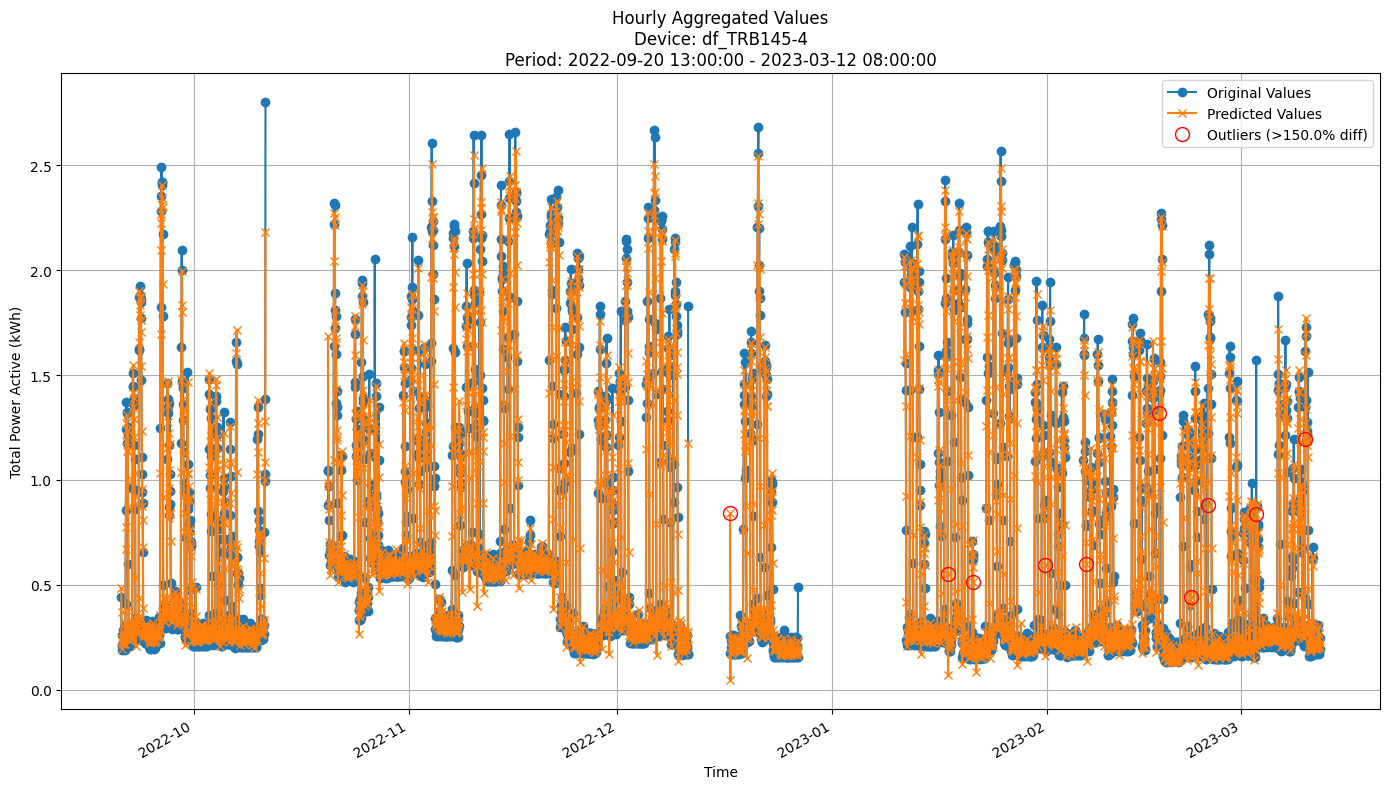


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1318
MAE: 0.0834
MAPE: 17.9739%

Directional Metrics:
Directional Accuracy: 40.7429%
First-Diff Correlation: 0.6111

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1053
  Recall: 0.0667
  F1 Score: 0.0816
Drops:
  Precision: 0.1111
  Recall: 0.0690
  F1 Score: 0.0851

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8421
  Recall: 0.5333
  F1 Score: 0.6531
Drops:
  Precision: 0.1667
  Recall: 0.1034
  F1 Score: 0.1277


In [23]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

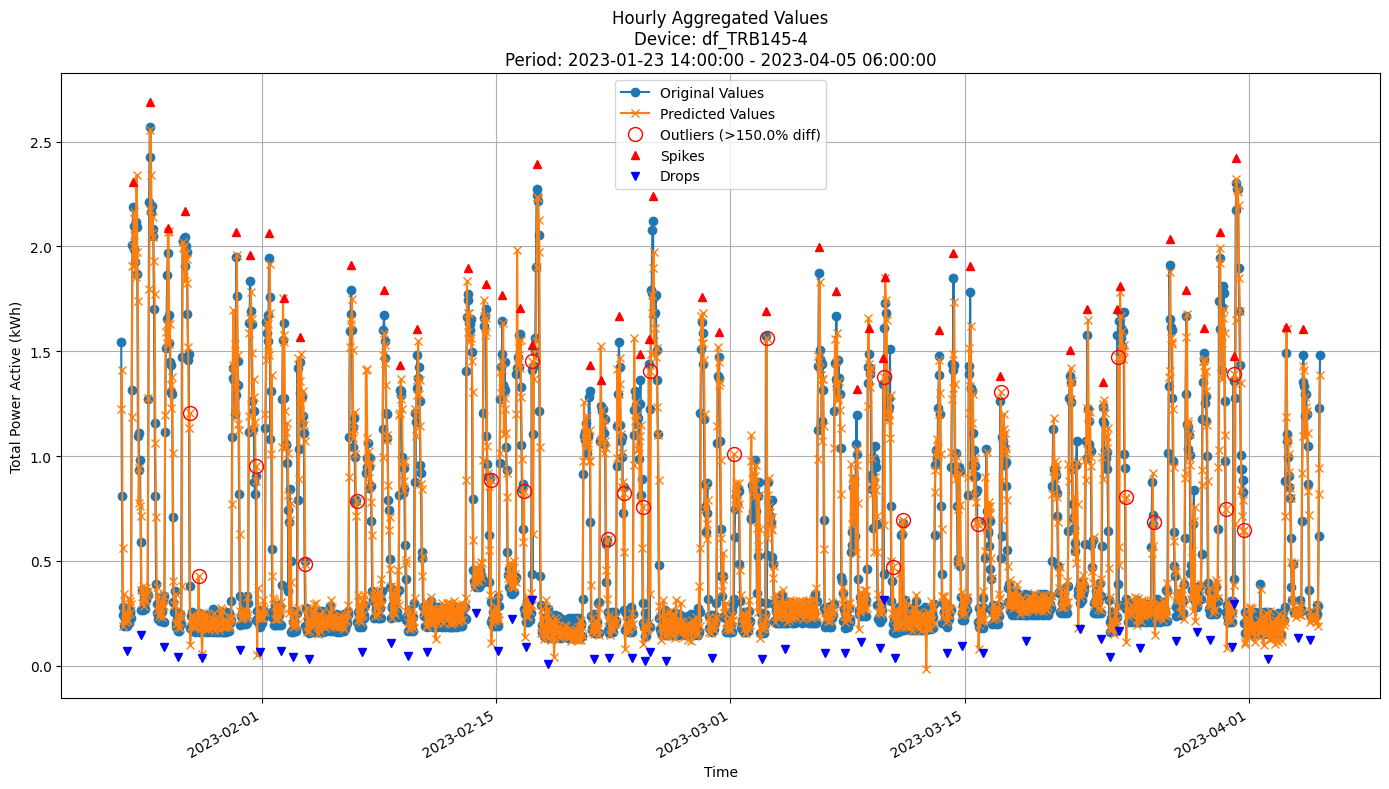


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1989
MAE: 0.1198
MAPE: 28.8068%

Directional Metrics:
Directional Accuracy: 36.2791%
First-Diff Correlation: 0.1927

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1591
  Recall: 0.1373
  F1 Score: 0.1474
Drops:
  Precision: 0.0222
  Recall: 0.0192
  F1 Score: 0.0206

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7955
  Recall: 0.6863
  F1 Score: 0.7368
Drops:
  Precision: 0.2222
  Recall: 0.1923
  F1 Score: 0.2062


In [24]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [25]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = dict(max_depth=10, grace_period=10, delta=0.5, tau=0.05, leaf_prediction="mean")


In [26]:

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00
Model's memory usage: 1.992241 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2617
	MAE: 0.1565
	MAPE: 19.7407%

Directional Metrics:
	Directional Accuracy: 37.0629%
	First-Diff Correlation: -0.0431

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.7143
		F1: 0.8333
	Drops:
		Precision: 0.2727
		Recall: 0.2143
		F1: 0.2400
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00
Model's memory usage: 3.380684 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2536
	MAE: 0.1590
	MAPE: 26.9909%

Directional Metrics:
	Directional Accuracy: 44.1536%
	First-Diff Correlation: 0.2652

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
----

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-02-16 11:00:00
Model's memory usage: 5.204857 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-16 12:00:00 - 2023-03-12 08:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2492
	MAE: 0.1501
	MAPE: 40.2371%

Directional Metrics:
	Directional Accuracy: 38.9860%
	First-Diff Correlation: -0.0340

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2143
		Recall: 0.1667
		F1: 0.1875
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6429
		Recall: 0.5000
		F1: 0.5625
	Drops:
		Precision: 0.3571
		Recall: 0.2778
		F1: 0.3125
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00
Model's memory usage: 4.949402 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2244
	MAE: 0.1419
	MAPE: 32.9030%

Directional Metrics:
	Directional Accuracy: 41.3613%
	First-Diff Correlation: 0.0745

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.4545
		Recall: 0.2941
		F1: 0.3571
	Drops:
		Precision: 0.0909
		Recall: 0.0588
		F1: 0.0714

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.6471
		F1: 0.7857
	Drops:
		Precision: 0.2727
		Recall: 0.1765
		F1: 0.2143
--------------------------------------------------
Daily Metrics:
----

#### Results

In [27]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2358 ± 0.0054
	MAE: 0.1407 ± 0.0041
	MAPE: 26.5922% ± 2.2234%

	Directional Metrics:
		Directional Accuracy: 39.7441% ± 0.9641%
		First-Diff Correlation: 0.1463 ± 0.0537

	Immediate Detection (delta=0):
		Spike Precision: 0.0076 ± 0.0169
		Spike Recall: 0.0056 ± 0.0124
		Spike F1: 0.0064 ± 0.0143
		Drop Precision: 0.0079 ± 0.0177
		Drop Recall: 0.0057 ± 0.0129
		Drop F1: 0.0067 ± 0.0149

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4394 ± 0.4558
		Spike Recall: 0.1556 ± 0.1988
		Spike F1: 0.2058 ± 0.2510
		Drop Precision: 0.0651 ± 0.0921
		Drop Recall: 0.0349 ± 0.0529
		Drop F1: 0.0442 ± 0.0645
Daily Metrics:
	RMSE: 0.7852 ± 0.0824
	MAE: 0.5370 ± 0.0679
	MAPE: 5.0680% ± 0.7166%

	Directional Metrics:
		Directional Accuracy: 92.8864% ± 1.4205%
		First-Diff Correlation: 0.9936 ± 0.0022

	Immediate Detection (delta=0):


#### Training plots
Plot only the last period of predictions

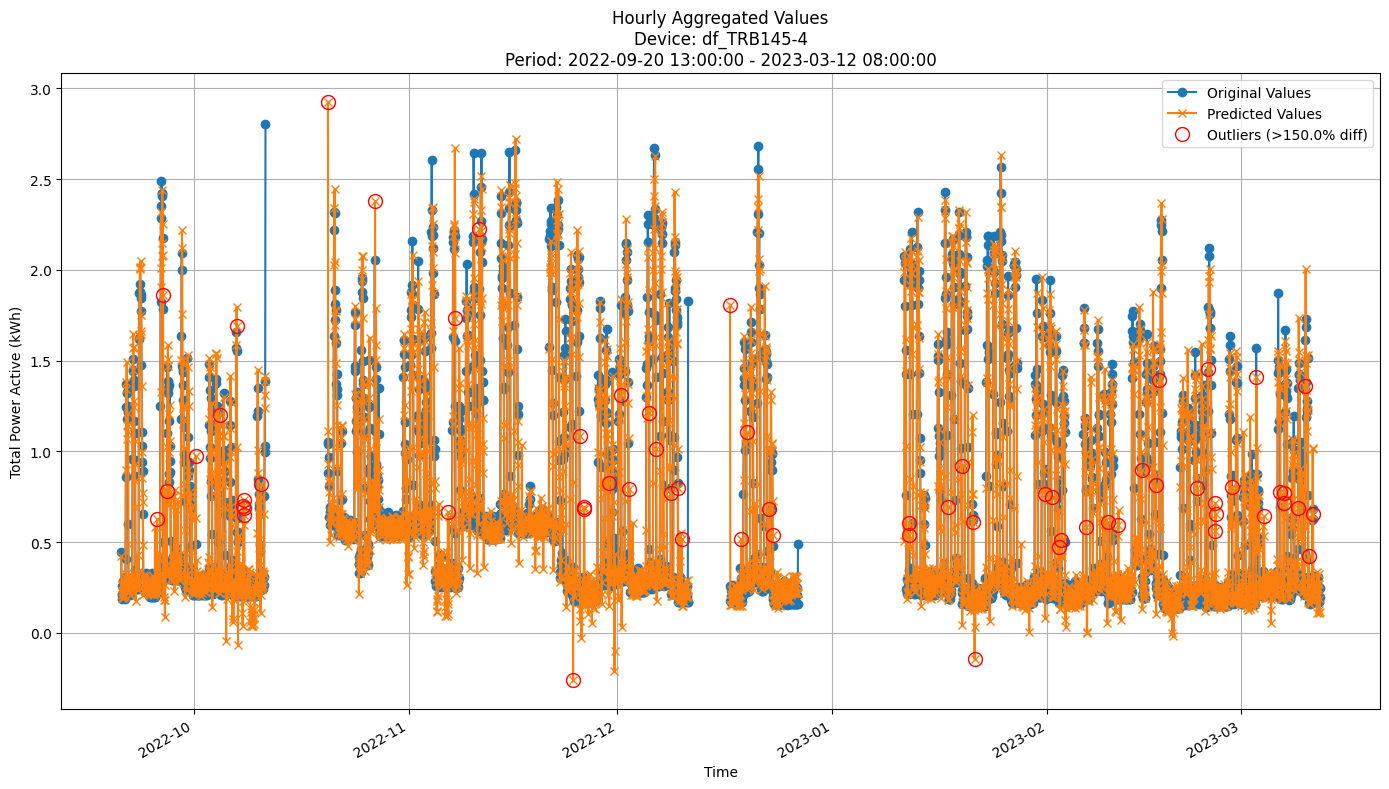


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2341
MAE: 0.1405
MAPE: 29.1710%

Directional Metrics:
Directional Accuracy: 40.9476%
First-Diff Correlation: 0.1809

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0455
  Recall: 0.0333
  F1 Score: 0.0385
Drops:
  Precision: 0.0476
  Recall: 0.0345
  F1 Score: 0.0400

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6364
  Recall: 0.4667
  F1 Score: 0.5385
Drops:
  Precision: 0.1905
  Recall: 0.1379
  F1 Score: 0.1600


In [28]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

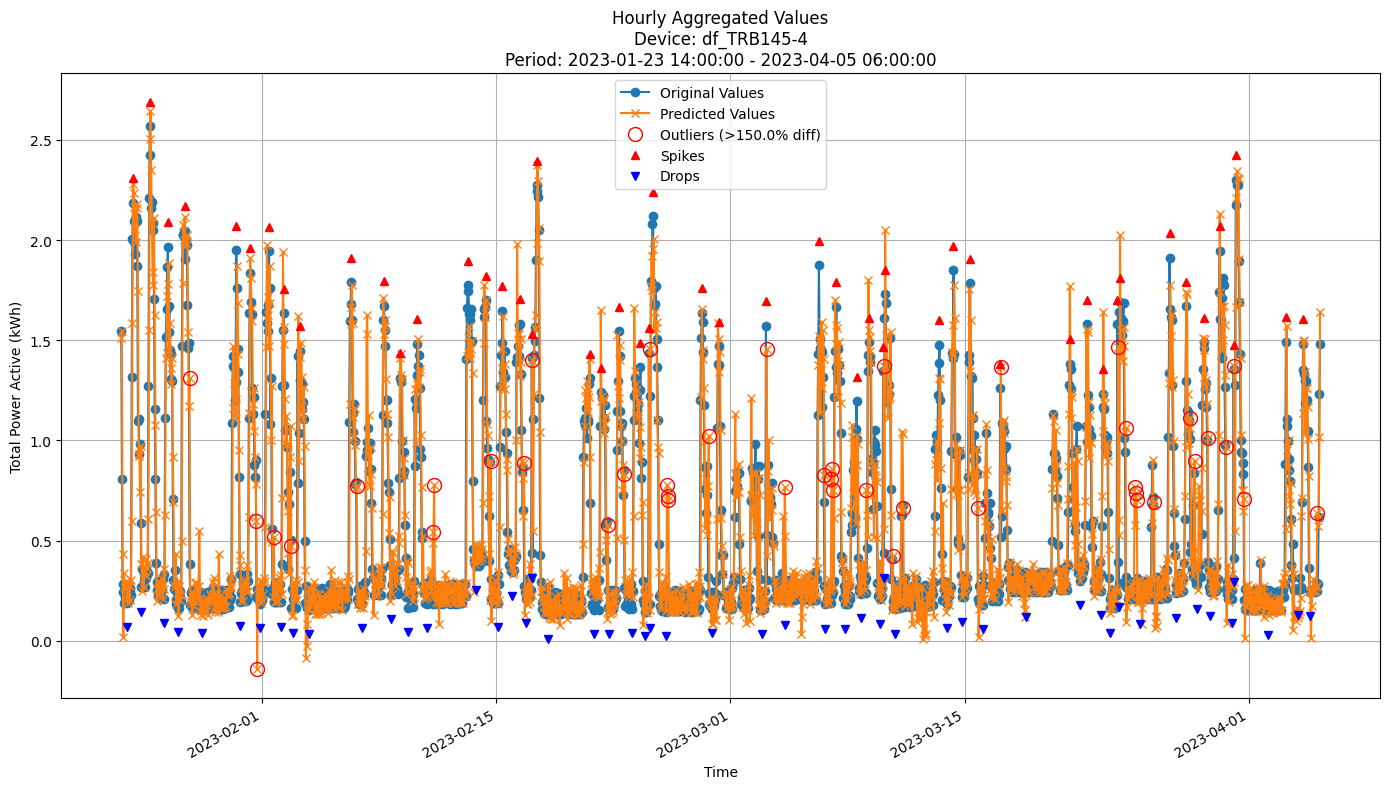


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2306
MAE: 0.1431
MAPE: 34.5643%

Directional Metrics:
Directional Accuracy: 41.2209%
First-Diff Correlation: 0.1162

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2000
  Recall: 0.1765
  F1 Score: 0.1875
Drops:
  Precision: 0.0217
  Recall: 0.0192
  F1 Score: 0.0204

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7556
  Recall: 0.6667
  F1 Score: 0.7083
Drops:
  Precision: 0.3913
  Recall: 0.3462
  F1 Score: 0.3673


In [29]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [30]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = dict(n_models=10, 
                     max_features=0.8, 
                     aggregation_method='median', 
                     grace_period=10, 
                     max_depth=10, 
                     delta=0.5, 
                     tau=0.01, 
                     seed=42)


In [31]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00
Model's memory usage: 11.679817 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2463
	MAE: 0.1454
	MAPE: 17.8418%

Directional Metrics:
	Directional Accuracy: 33.0420%
	First-Diff Correlation: -0.0439

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.7857
		F1: 0.8800
	Drops:
		Precision: 0.5455
		Recall: 0.4286
		F1: 0.4800
--------------------------------------------------
Daily Metrics:
--

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00
Model's memory usage: 14.778236 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2406
	MAE: 0.1412
	MAPE: 23.1135%

Directional Metrics:
	Directional Accuracy: 36.6492%
	First-Diff Correlation: 0.2719

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-02-16 11:00:00
Model's memory usage: 21.378120 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-16 12:00:00 - 2023-03-12 08:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2218
	MAE: 0.1271
	MAPE: 32.3567%

Directional Metrics:
	Directional Accuracy: 35.8392%
	First-Diff Correlation: -0.0434

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0667
		Recall: 0.0556
		F1: 0.0606
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9333
		Recall: 0.7778
		F1: 0.8485
	Drops:
		Precision: 0.4000
		Recall: 0.3333
		F1: 0.3636
--------------------------------------------------
Daily Metrics:
--

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00
Model's memory usage: 23.658234 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2109
	MAE: 0.1275
	MAPE: 28.4906%

Directional Metrics:
	Directional Accuracy: 38.9180%
	First-Diff Correlation: 0.0341

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1875
		Recall: 0.1765
		F1: 0.1818
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.9412
		F1: 0.9697
	Drops:
		Precision: 0.5625
		Recall: 0.5294
		F1: 0.5455
--------------------------------------------------
Daily Metrics:
---

#### Results

In [32]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2223 ± 0.0050
	MAE: 0.1286 ± 0.0028
	MAPE: 23.3126% ± 1.6404%

	Directional Metrics:
		Directional Accuracy: 35.3111% ± 2.0539%
		First-Diff Correlation: 0.1528 ± 0.0586

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.4810
		Spike Recall: 0.3500 ± 0.3905
		Spike F1: 0.3915 ± 0.4106
		Drop Precision: 0.1508 ± 0.1592
		Drop Recall: 0.1174 ± 0.1449
		Drop F1: 0.1283 ± 0.1497
Daily Metrics:
	RMSE: 0.4160 ± 0.0696
	MAE: 0.2571 ± 0.0296
	MAPE: 2.5591% ± 0.3673%

	Directional Metrics:
		Directional Accuracy: 93.5928% ± 1.3183%
		First-Diff Correlation: 0.9981 ± 0.0007

	Immediate Detection (delta=0):


#### Training plots

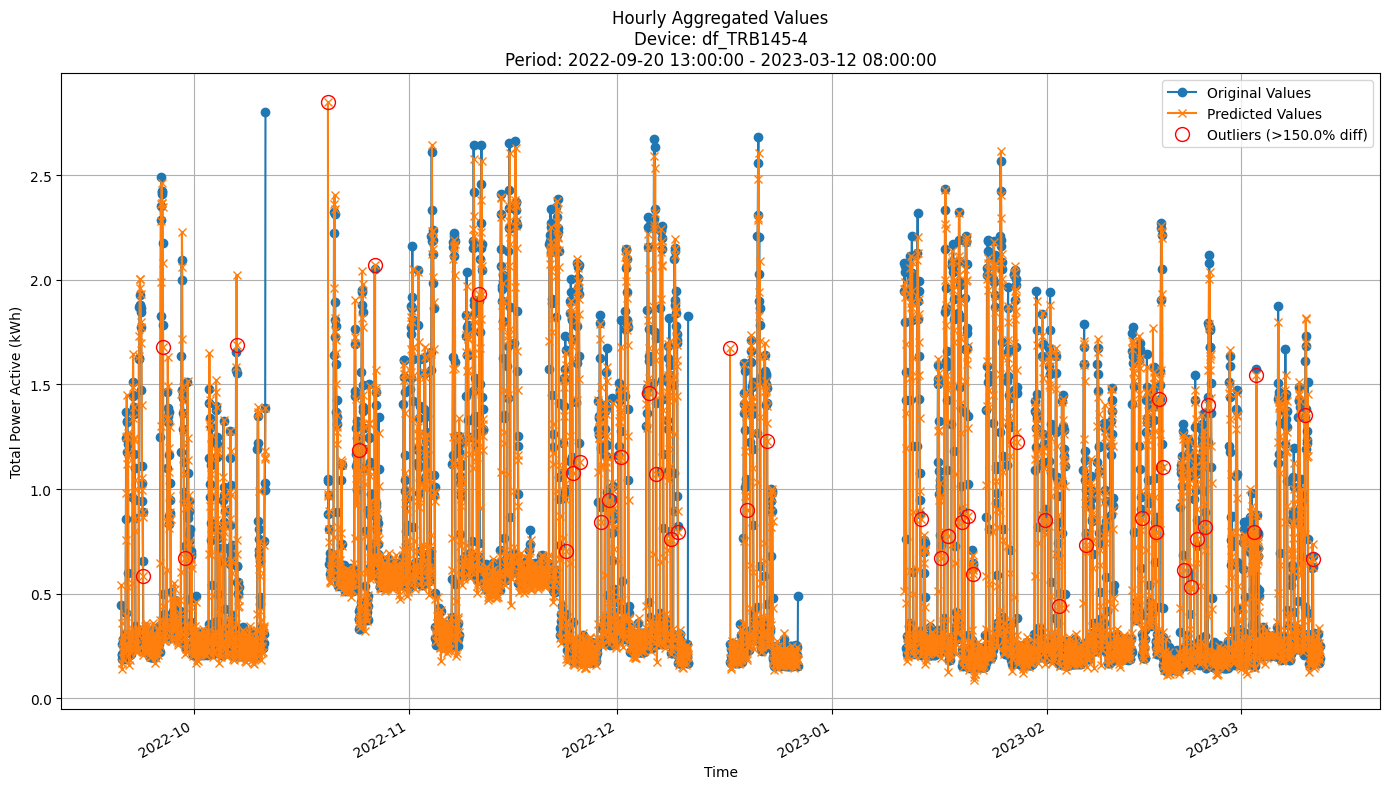


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2158
MAE: 0.1261
MAPE: 25.1534%

Directional Metrics:
Directional Accuracy: 36.7066%
First-Diff Correlation: 0.1893

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8750
  Recall: 0.7000
  F1 Score: 0.7778
Drops:
  Precision: 0.3478
  Recall: 0.2759
  F1 Score: 0.3077


In [33]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

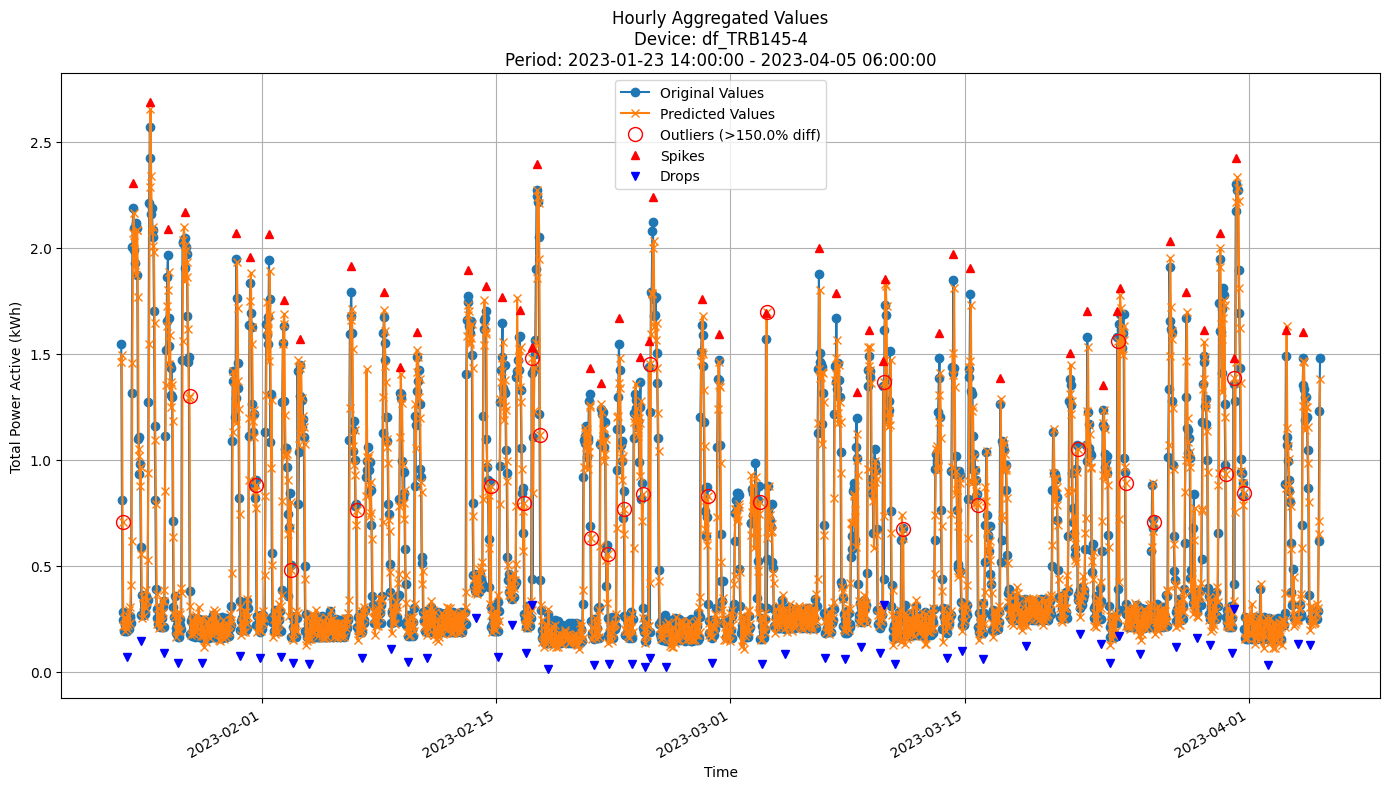


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2113
MAE: 0.1263
MAPE: 29.7424%

Directional Metrics:
Directional Accuracy: 37.3837%
First-Diff Correlation: 0.0990

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1304
  Recall: 0.1176
  F1 Score: 0.1237
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8696
  Recall: 0.7843
  F1 Score: 0.8247
Drops:
  Precision: 0.4468
  Recall: 0.4038
  F1 Score: 0.4242


In [34]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [35]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT

fodt_params = {'depth': 50, 
               'grace_period': 24, 
               'grace_period_depth': 0, 
               'split_confidence': 0.005, 
               'max_feature': 0.3, 
               'tie_threshold': 0.05, 
               'bin_type': 'mean', 
               'split_criterion': 'vr_rel'}

In [36]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt, 
    model_params=fodt_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00
Model's memory usage: 0.025345 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2601
	MAE: 0.1511
	MAPE: 18.0019%

Directional Metrics:
	Directional Accuracy: 33.0420%
	First-Diff Correlation: -0.0586

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00
Model's memory usage: 0.079498 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2449
	MAE: 0.1471
	MAPE: 24.1532%

Directional Metrics:
	Directional Accuracy: 37.3473%
	First-Diff Correlation: 0.3077

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
----

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-02-16 11:00:00
Model's memory usage: 0.054665 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-16 12:00:00 - 2023-03-12 08:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2484
	MAE: 0.1461
	MAPE: 39.9753%

Directional Metrics:
	Directional Accuracy: 34.6154%
	First-Diff Correlation: -0.1272

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0625
		Recall: 0.0556
		F1: 0.0588
	Drops:
		Precision: 0.0625
		Recall: 0.0556
		F1: 0.0588

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.8889
		F1: 0.9412
	Drops:
		Precision: 0.6250
		Recall: 0.5556
		F1: 0.5882
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00
Model's memory usage: 0.055893 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2280
	MAE: 0.1376
	MAPE: 29.3758%

Directional Metrics:
	Directional Accuracy: 37.5218%
	First-Diff Correlation: 0.0421

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8947
		Recall: 1.0000
		F1: 0.9444
	Drops:
		Precision: 0.5263
		Recall: 0.5882
		F1: 0.5556
--------------------------------------------------
Daily Metrics:
----

#### Results

In [37]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2967 ± 0.1173
	MAE: 0.1999 ± 0.1225
	MAPE: 44.1698% ± 37.1358%

	Directional Metrics:
		Directional Accuracy: 34.9939% ± 1.4353%
		First-Diff Correlation: 0.0848 ± 0.0559

	Immediate Detection (delta=0):
		Spike Precision: 0.0045 ± 0.0101
		Spike Recall: 0.0056 ± 0.0124
		Spike F1: 0.0050 ± 0.0111
		Drop Precision: 0.0139 ± 0.0311
		Drop Recall: 0.0172 ± 0.0386
		Drop F1: 0.0154 ± 0.0344

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4505 ± 0.4612
		Spike Recall: 0.3444 ± 0.4241
		Spike F1: 0.3516 ± 0.4025
		Drop Precision: 0.2454 ± 0.3790
		Drop Recall: 0.2644 ± 0.3925
		Drop F1: 0.2538 ± 0.3845
Daily Metrics:
	RMSE: 2.2480 ± 3.5243
	MAE: 1.7437 ± 3.0234
	MAPE: 16.8592% ± 28.5101%

	Directional Metrics:
		Directional Accuracy: 95.5761% ± 3.4425%
		First-Diff Correlation: 0.9790 ± 0.0362

	Immediate Detection (delta=0

#### Training plots


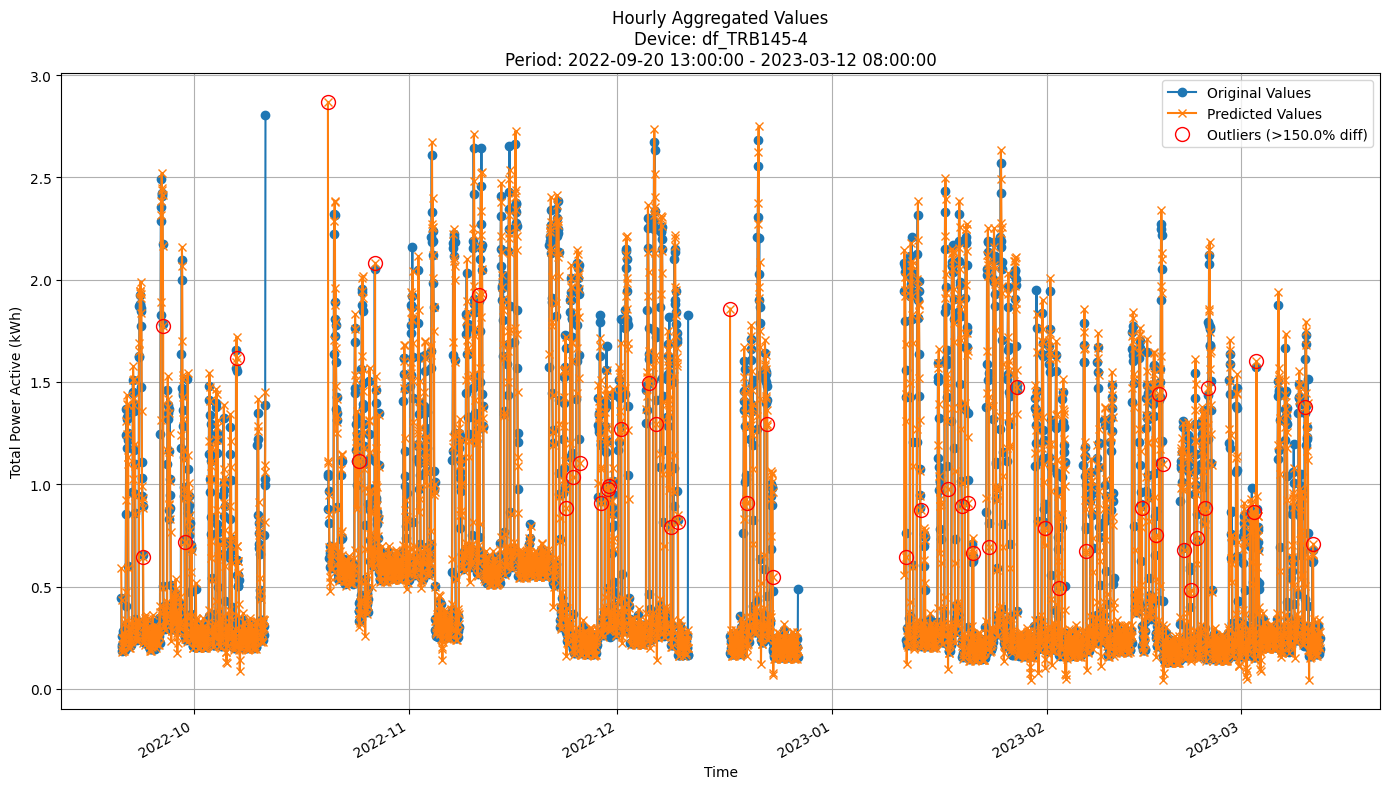


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2445
MAE: 0.1407
MAPE: 27.5081%

Directional Metrics:
Directional Accuracy: 35.7999%
First-Diff Correlation: 0.0966

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0270
  Recall: 0.0333
  F1 Score: 0.0299
Drops:
  Precision: 0.0833
  Recall: 0.1034
  F1 Score: 0.0923

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7027
  Recall: 0.8667
  F1 Score: 0.7761
Drops:
  Precision: 0.4722
  Recall: 0.5862
  F1 Score: 0.5231


In [38]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id,
                            spike_prominence=SPIKE_PROMINENCE, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

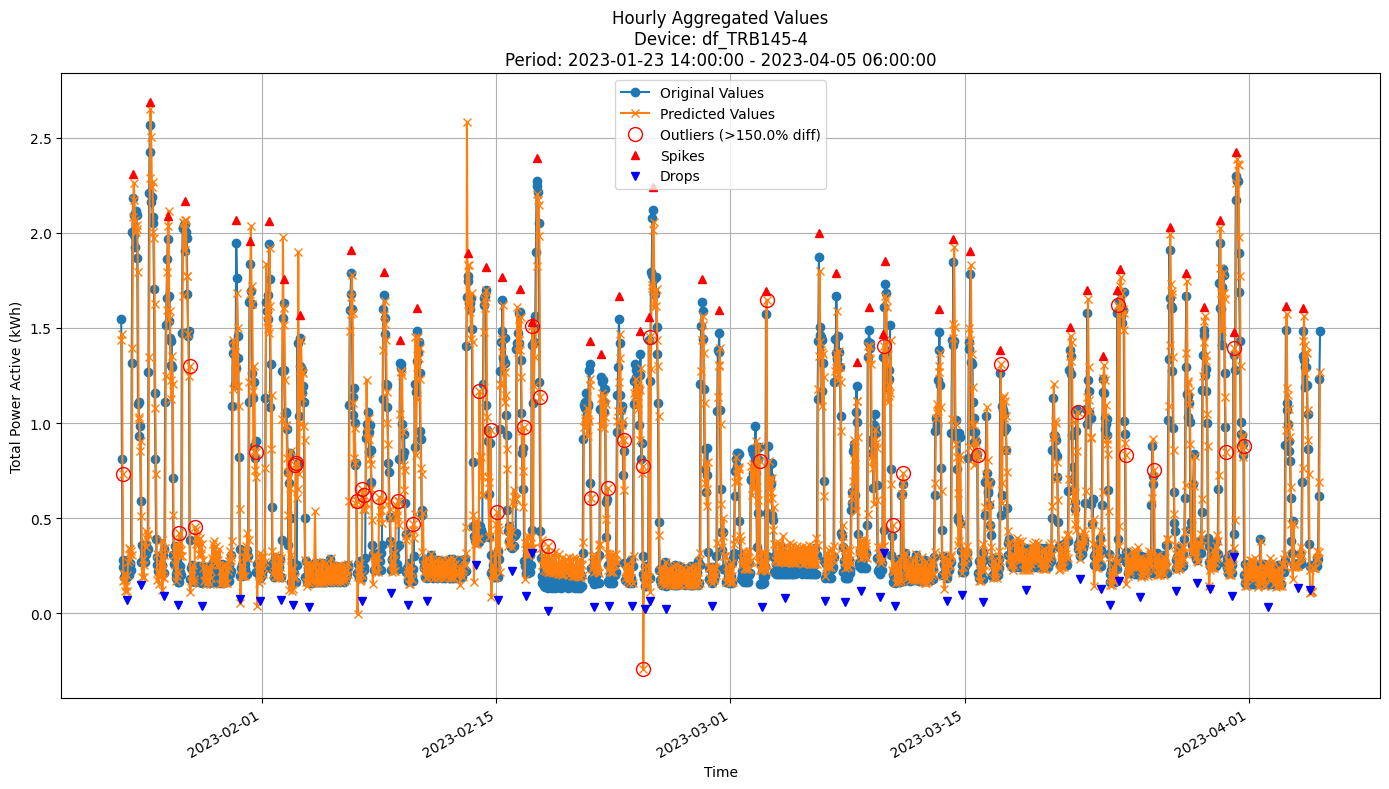


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2372
MAE: 0.1457
MAPE: 35.2491%

Directional Metrics:
Directional Accuracy: 36.5698%
First-Diff Correlation: 0.0562

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0227
  Recall: 0.0196
  F1 Score: 0.0211
Drops:
  Precision: 0.0444
  Recall: 0.0385
  F1 Score: 0.0412

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9318
  Recall: 0.8039
  F1 Score: 0.8632
Drops:
  Precision: 0.4667
  Recall: 0.4038
  F1 Score: 0.4330


In [39]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### xFastODT

In [40]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

xfodt = xfastodt.xFastODT

xfodt_params = {'depth': 50, 
               'grace_period': 12, 
               'grace_period_depth': 0, 
               'split_confidence': 0.005, 
               'max_feature': 1.0, 
               'tie_threshold': 0.05, 
               'bin_type': 'mean', 
               'split_criterion': 'vr_rel'}

In [41]:
xfodt_all_train_preds, xfodt_all_valid_preds, \
xfodt_all_train_metrics, xfodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=xfodt, 
    model_params=xfodt_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00
Model's memory usage: 0.071518 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2604
	MAE: 0.1513
	MAPE: 17.9753%

Directional Metrics:
	Directional Accuracy: 33.3916%
	First-Diff Correlation: -0.0592

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0714
		Recall: 0.0714
		F1: 0.0714

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00
Model's memory usage: 4.646347 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2602
	MAE: 0.1649
	MAPE: 29.6493%

Directional Metrics:
	Directional Accuracy: 36.4747%
	First-Diff Correlation: 0.1916

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
----

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-02-16 11:00:00
Model's memory usage: 37.151627 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-16 12:00:00 - 2023-03-12 08:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2064
	MAE: 0.1313
	MAPE: 37.2033%

Directional Metrics:
	Directional Accuracy: 37.5874%
	First-Diff Correlation: 0.1818

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0625
		Recall: 0.0556
		F1: 0.0588
	Drops:
		Precision: 0.0625
		Recall: 0.0556
		F1: 0.0588

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6875
		Recall: 0.6111
		F1: 0.6471
	Drops:
		Precision: 0.3125
		Recall: 0.2778
		F1: 0.2941
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00
Model's memory usage: 50.538551 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2058
	MAE: 0.1332
	MAPE: 32.0180%

Directional Metrics:
	Directional Accuracy: 41.7103%
	First-Diff Correlation: 0.2184

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.1765
		F1: 0.1875
	Drops:
		Precision: 0.0667
		Recall: 0.0588
		F1: 0.0625

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9333
		Recall: 0.8235
		F1: 0.8750
	Drops:
		Precision: 0.3333
		Recall: 0.2941
		F1: 0.3125
--------------------------------------------------
Daily Metrics:
---

#### Results

In [42]:
print("\n\nTrain period metrics:")
xfodt_all_time_train_metrics = all_time_aggregation_metrics(xfodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
xfodt_all_time_valid_metrics = all_time_aggregation_metrics(xfodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2246 ± 0.0162
	MAE: 0.1377 ± 0.0097
	MAPE: 26.2936% ± 1.0506%

	Directional Metrics:
		Directional Accuracy: 39.2387% ± 4.8707%
		First-Diff Correlation: 0.1951 ± 0.1281

	Immediate Detection (delta=0):
		Spike Precision: 0.0044 ± 0.0098
		Spike Recall: 0.0056 ± 0.0124
		Spike F1: 0.0049 ± 0.0110
		Drop Precision: 0.0090 ± 0.0201
		Drop Recall: 0.0115 ± 0.0257
		Drop F1: 0.0101 ± 0.0226

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3592 ± 0.3861
		Spike Recall: 0.4167 ± 0.4250
		Spike F1: 0.3842 ± 0.4015
		Drop Precision: 0.1935 ± 0.3628
		Drop Recall: 0.2016 ± 0.3606
		Drop F1: 0.1970 ± 0.3618
Daily Metrics:
	RMSE: 0.7707 ± 0.1243
	MAE: 0.5032 ± 0.1779
	MAPE: 5.0223% ± 1.5465%

	Directional Metrics:
		Directional Accuracy: 96.4119% ± 2.5930%
		First-Diff Correlation: 0.9946 ± 0.0008

	Immediate Detection (delta=0):


#### Training plots


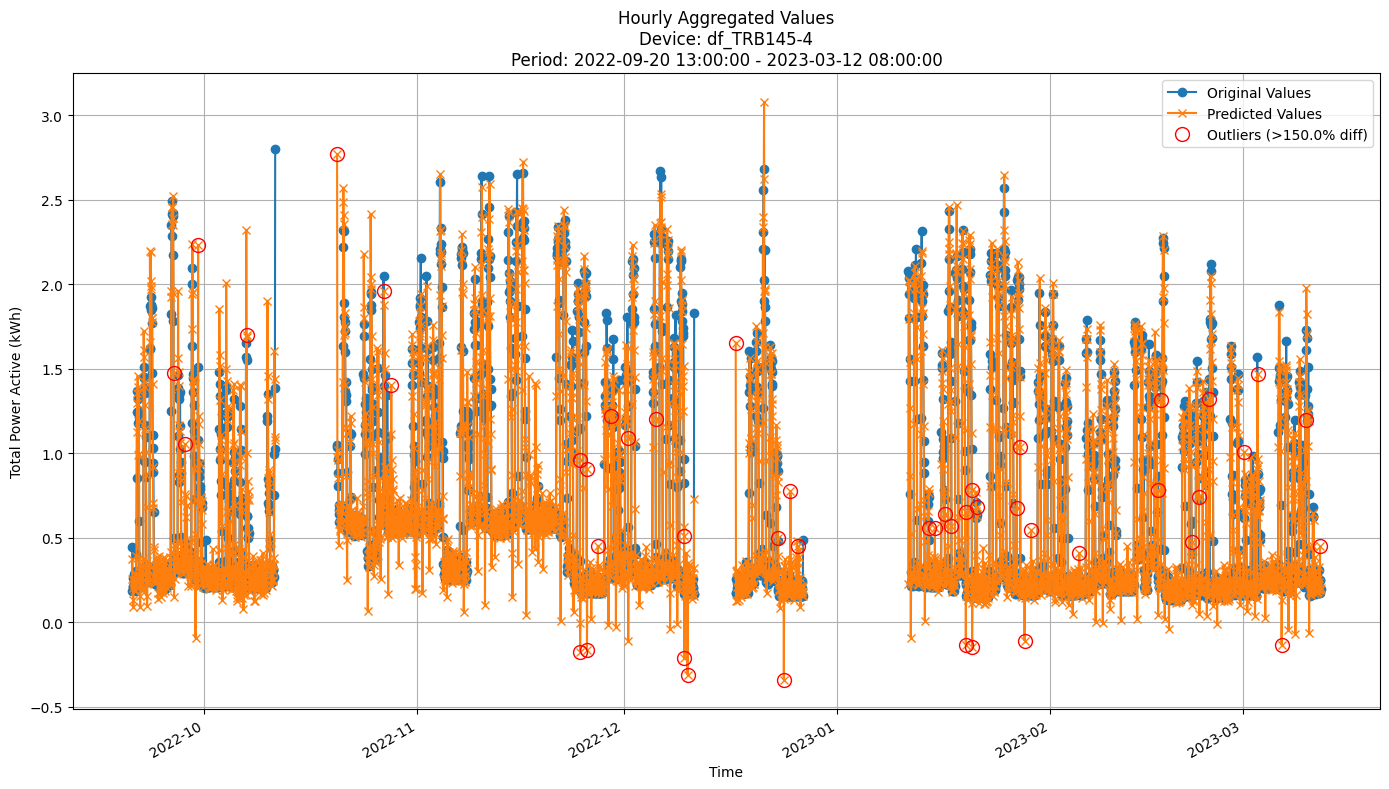


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2014
MAE: 0.1255
MAPE: 26.9811%

Directional Metrics:
Directional Accuracy: 42.8195%
First-Diff Correlation: 0.3245

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0263
  Recall: 0.0333
  F1 Score: 0.0294
Drops:
  Precision: 0.0541
  Recall: 0.0690
  F1 Score: 0.0606

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6053
  Recall: 0.7667
  F1 Score: 0.6765
Drops:
  Precision: 0.1081
  Recall: 0.1379
  F1 Score: 0.1212


In [43]:
for device_id in xfodt_all_train_preds.keys():
    y_train = xfodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = xfodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id,
                            spike_prominence=SPIKE_PROMINENCE, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

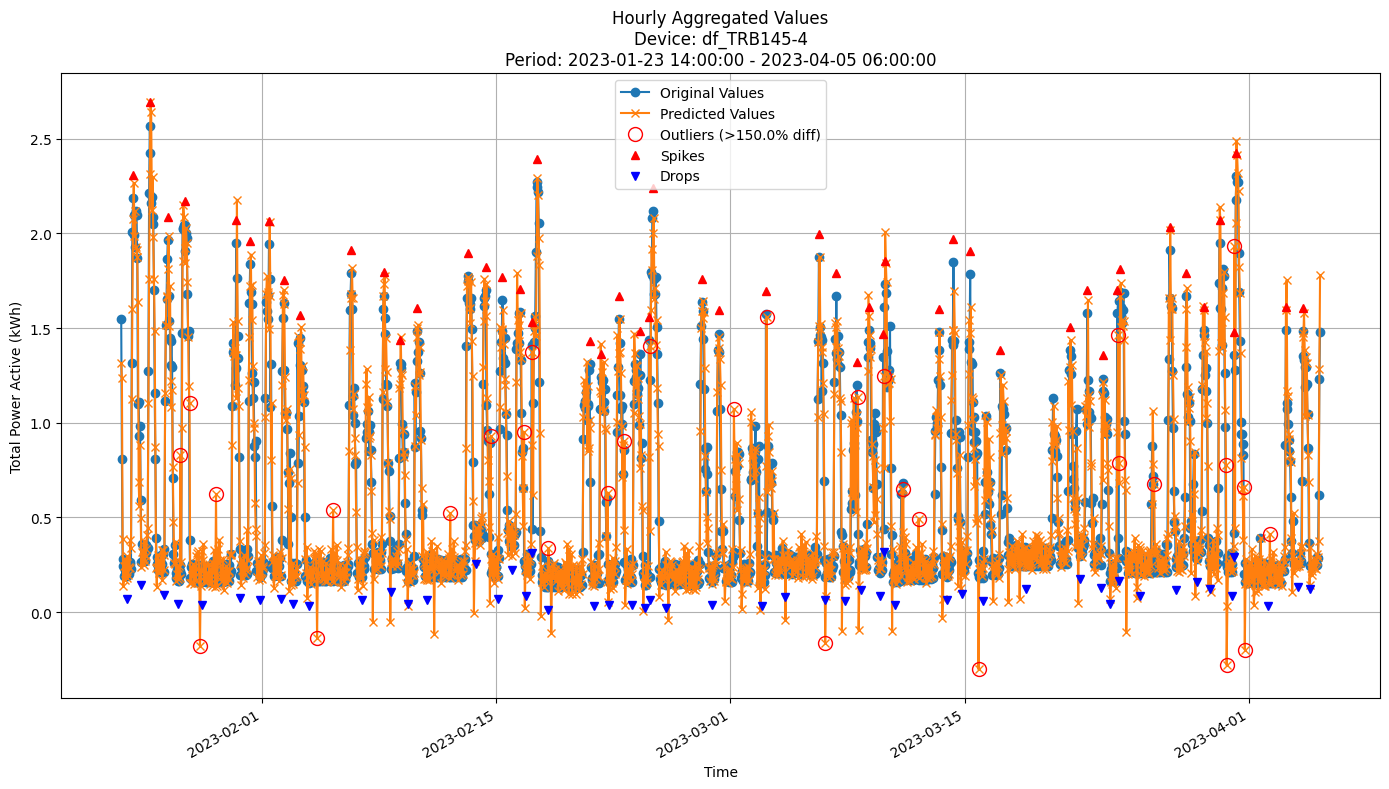


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1954
MAE: 0.1266
MAPE: 32.6040%

Directional Metrics:
Directional Accuracy: 40.6977%
First-Diff Correlation: 0.2849

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1064
  Recall: 0.0980
  F1 Score: 0.1020
Drops:
  Precision: 0.0625
  Recall: 0.0577
  F1 Score: 0.0600

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8298
  Recall: 0.7647
  F1 Score: 0.7959
Drops:
  Precision: 0.3125
  Recall: 0.2885
  F1 Score: 0.3000


In [44]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in xfodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, xfodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, xfodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [45]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = dict(n_models=20, 
                  aggregation_method="mean", 
                  grace_period=0,  # by default works for all leaves
                  disable_weighted_vote=True,
                  max_depth=50, 
                  delta=0.05, 
                  tau=0.01, 
                  seed=42, 
                  max_features=0.7, 
                  bin_type='mean', 
                  max_bins=1,
                  split_criterion='vr_rel',)


In [46]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00
Model's memory usage: 366.392799 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3094
	MAE: 0.1831
	MAPE: 23.6638%

Directional Metrics:
	Directional Accuracy: 46.1538%
	First-Diff Correlation: -0.0548

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1250
		Recall: 0.0714
		F1: 0.0909
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7500
		Recall: 0.4286
		F1: 0.5455
	Drops:
		Precision: 0.1429
		Recall: 0.0714
		F1: 0.0952
--------------------------------------------------
Daily Metrics:
-

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00
Model's memory usage: 561.748573 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2639
	MAE: 0.1724
	MAPE: 30.3204%

Directional Metrics:
	Directional Accuracy: 47.2949%
	First-Diff Correlation: 0.2738

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-02-16 11:00:00
Model's memory usage: 1213.410149 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-16 12:00:00 - 2023-03-12 08:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2632
	MAE: 0.1626
	MAPE: 45.1738%

Directional Metrics:
	Directional Accuracy: 44.4056%
	First-Diff Correlation: 0.0566

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1667
		Recall: 0.1111
		F1: 0.1333
	Drops:
		Precision: 0.0833
		Recall: 0.0556
		F1: 0.0667

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6667
		Recall: 0.4444
		F1: 0.5333
	Drops:
		Precision: 0.2500
		Recall: 0.1667
		F1: 0.2000
--------------------------------------------------
Daily Metrics:
-

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00
Model's memory usage: 1300.058762 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2533
	MAE: 0.1636
	MAPE: 39.6162%

Directional Metrics:
	Directional Accuracy: 45.3752%
	First-Diff Correlation: 0.0386

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.1765
		F1: 0.1875
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8667
		Recall: 0.7647
		F1: 0.8125
	Drops:
		Precision: 0.2000
		Recall: 0.1765
		F1: 0.1875
--------------------------------------------------
Daily Metrics:
-

#### Results

In [47]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1840 ± 0.0127
	MAE: 0.0771 ± 0.0121
	MAPE: 15.4241% ± 3.9845%

	Directional Metrics:
		Directional Accuracy: 74.4048% ± 5.5213%
		First-Diff Correlation: 0.5606 ± 0.0479

	Immediate Detection (delta=0):
		Spike Precision: 0.1570 ± 0.1740
		Spike Recall: 0.1556 ± 0.1750
		Spike F1: 0.1545 ± 0.1712
		Drop Precision: 0.0461 ± 0.0493
		Drop Recall: 0.0468 ± 0.0518
		Drop F1: 0.0458 ± 0.0494

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2933 ± 0.3045
		Spike Recall: 0.2889 ± 0.2923
		Spike F1: 0.2875 ± 0.2911
		Drop Precision: 0.1216 ± 0.1336
		Drop Recall: 0.1285 ± 0.1519
		Drop F1: 0.1235 ± 0.1407
Daily Metrics:
	RMSE: 0.4732 ± 0.0172
	MAE: 0.2428 ± 0.0274
	MAPE: 1.7664% ± 0.1357%

	Directional Metrics:
		Directional Accuracy: 95.3089% ± 0.9393%
		First-Diff Correlation: 0.9972 ± 0.0004

	Immediate Detection (delta=0):


#### Training plots

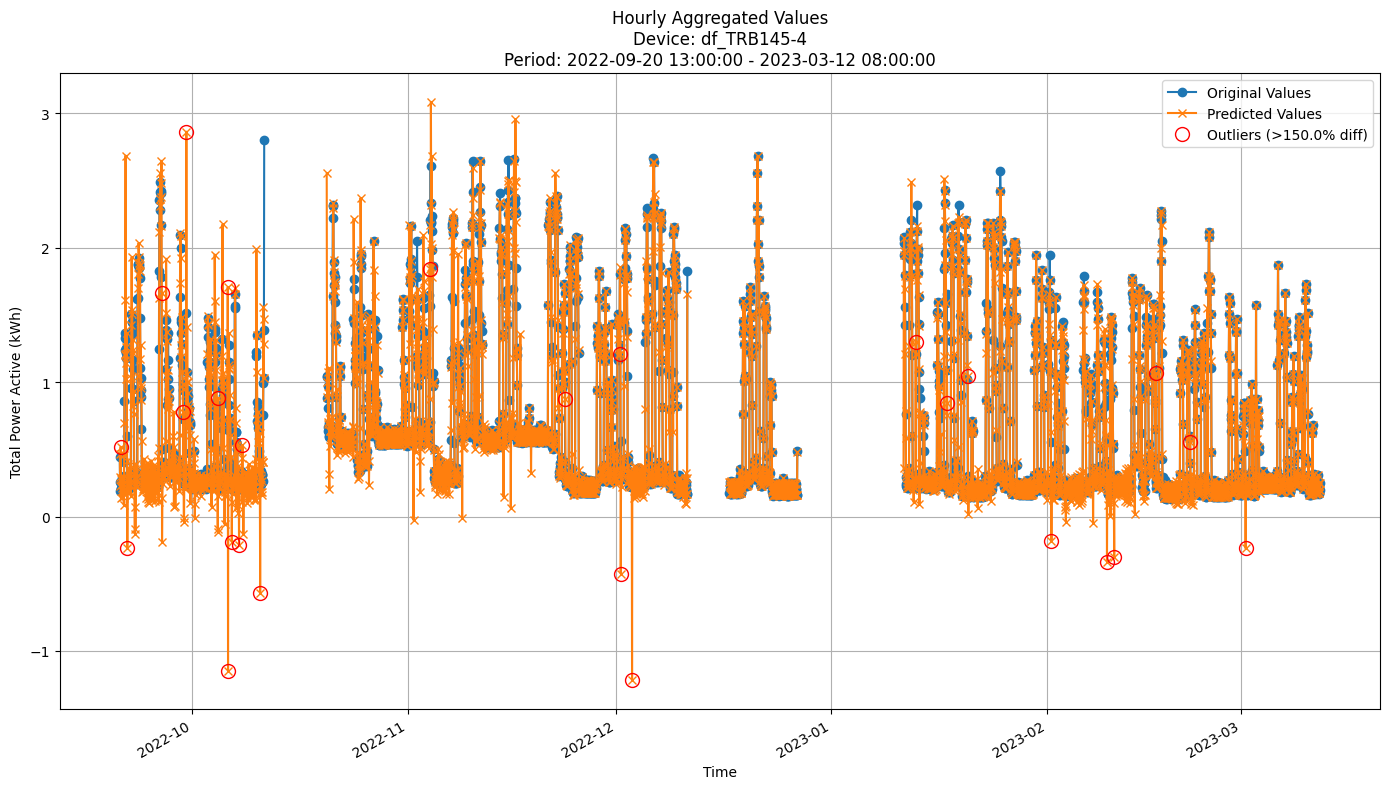


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1652
MAE: 0.0627
MAPE: 12.6513%

Directional Metrics:
Directional Accuracy: 78.8535%
First-Diff Correlation: 0.6269

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4118
  Recall: 0.4667
  F1 Score: 0.4375
Drops:
  Precision: 0.1176
  Recall: 0.1379
  F1 Score: 0.1270

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5882
  Recall: 0.6667
  F1 Score: 0.6250
Drops:
  Precision: 0.3529
  Recall: 0.4138
  F1 Score: 0.3810


In [48]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

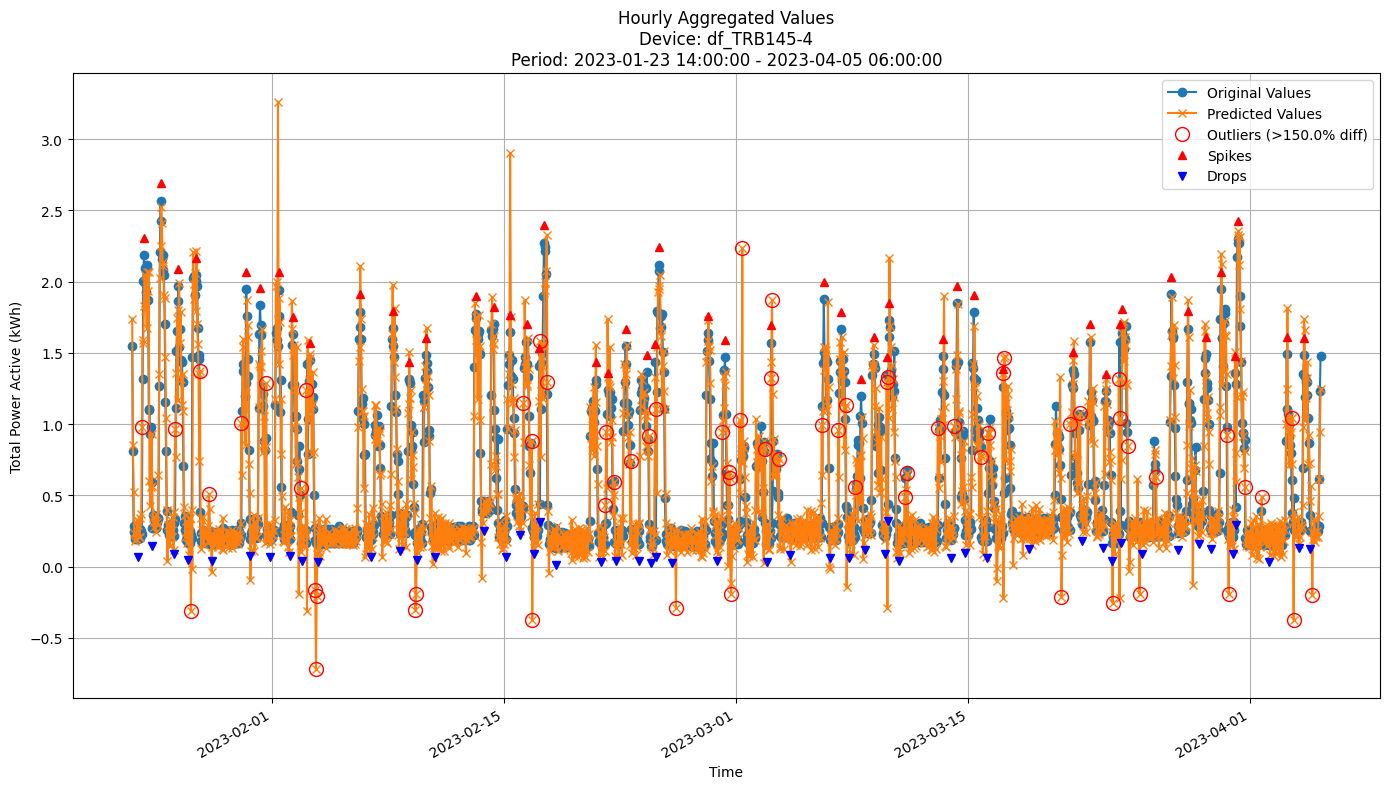


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2605
MAE: 0.1614
MAPE: 39.8397%

Directional Metrics:
Directional Accuracy: 46.9767%
First-Diff Correlation: 0.0950

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1905
  Recall: 0.1569
  F1 Score: 0.1720
Drops:
  Precision: 0.0714
  Recall: 0.0577
  F1 Score: 0.0638

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6905
  Recall: 0.5686
  F1 Score: 0.6237
Drops:
  Precision: 0.2381
  Recall: 0.1923
  F1 Score: 0.2128


In [49]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [50]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

split_confidence_hf = 0.01
grace_period = 24
depth = 50
eagerness = 0
bin_type = 'mean'  # 'mean' or 'adaptive'
max_bins = 1
# max_bins = 32  # for adaptive binning
max_features = 0.7
tie_threshold = 0.05
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes

incb = IncubationBoost
incb_params = dict(
    length=20,
    learning_rate=0.5,
    depth=depth,
    grace_period=grace_period,
    split_confidence=split_confidence_hf,
    eagerness=eagerness,
    grace_period_depth=grace_period_depth,
    bin_type=bin_type,
    max_bins=max_bins,
    max_feature=max_features,
    tie_threshold=tie_threshold,
    split_criterion='vr_rel',
    verbose=False
)

In [51]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/6 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-10-22 12:00:00
Model's memory usage: 0.097038 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2592
	MAE: 0.1514
	MAPE: 18.1269%

Directional Metrics:
	Directional Accuracy: 32.6923%
	First-Diff Correlation: -0.0512

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0714
		Recall: 0.0714
		F1: 0.0714
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.7857
		Recall: 0.7857
		F1: 0.7857
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2022-11-15 09:00:00
Model's memory usage: 0.253326 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2327
	MAE: 0.1397
	MAPE: 23.3495%

Directional Metrics:
	Directional Accuracy: 38.5689%
	First-Diff Correlation: 0.2979

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
----

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Processing devices in split 4:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-02-16 11:00:00
Model's memory usage: 0.644447 MB
Metrics for Device: df_TRB145-4 | Period: 2023-02-16 12:00:00 - 2023-03-12 08:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2479
	MAE: 0.1420
	MAPE: 36.1022%

Directional Metrics:
	Directional Accuracy: 34.7902%
	First-Diff Correlation: -0.1175

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.9444
		F1: 0.9714
	Drops:
		Precision: 0.7647
		Recall: 0.7222
		F1: 0.7429
--------------------------------------------------
Daily Metrics:
---

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-03-12 08:00:00
Model's memory usage: 0.863106 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2184
	MAE: 0.1308
	MAPE: 28.6191%

Directional Metrics:
	Directional Accuracy: 38.2199%
	First-Diff Correlation: 0.0562

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1176
		F1: 0.1290
	Drops:
		Precision: 0.0769
		Recall: 0.0588
		F1: 0.0667

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.8235
		F1: 0.9032
	Drops:
		Precision: 0.4615
		Recall: 0.3529
		F1: 0.4000
--------------------------------------------------
Daily Metrics:
----

#### Results

In [52]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2372 ± 0.0075
	MAE: 0.1366 ± 0.0044
	MAPE: 24.4934% ± 1.6561%

	Directional Metrics:
		Directional Accuracy: 34.4979% ± 1.4019%
		First-Diff Correlation: 0.1123 ± 0.0506

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4896 ± 0.4900
		Spike Recall: 0.3500 ± 0.3819
		Spike F1: 0.4004 ± 0.4135
		Drop Precision: 0.2556 ± 0.3857
		Drop Recall: 0.2126 ± 0.3662
		Drop F1: 0.2273 ± 0.3702
Daily Metrics:
	RMSE: 0.5196 ± 0.0680
	MAE: 0.2790 ± 0.0641
	MAPE: 2.7847% ± 0.4117%

	Directional Metrics:
		Directional Accuracy: 97.9281% ± 1.5614%
		First-Diff Correlation: 0.9969 ± 0.0008

	Immediate Detection (delta=0):


#### Train plots

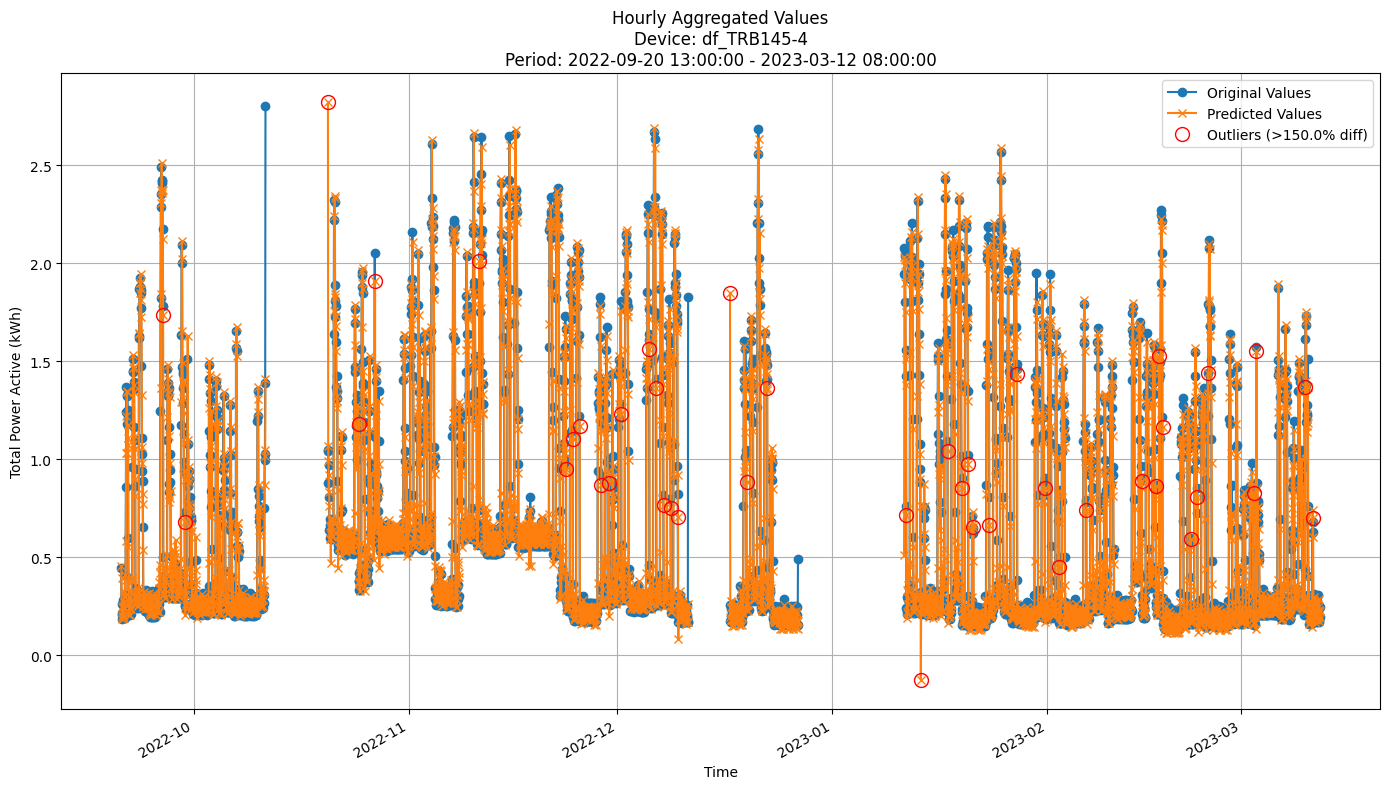


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2383
MAE: 0.1361
MAPE: 26.1653%

Directional Metrics:
Directional Accuracy: 35.0102%
First-Diff Correlation: 0.1197

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9375
  Recall: 0.5000
  F1 Score: 0.6522
Drops:
  Precision: 0.5333
  Recall: 0.2759
  F1 Score: 0.3636


In [53]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

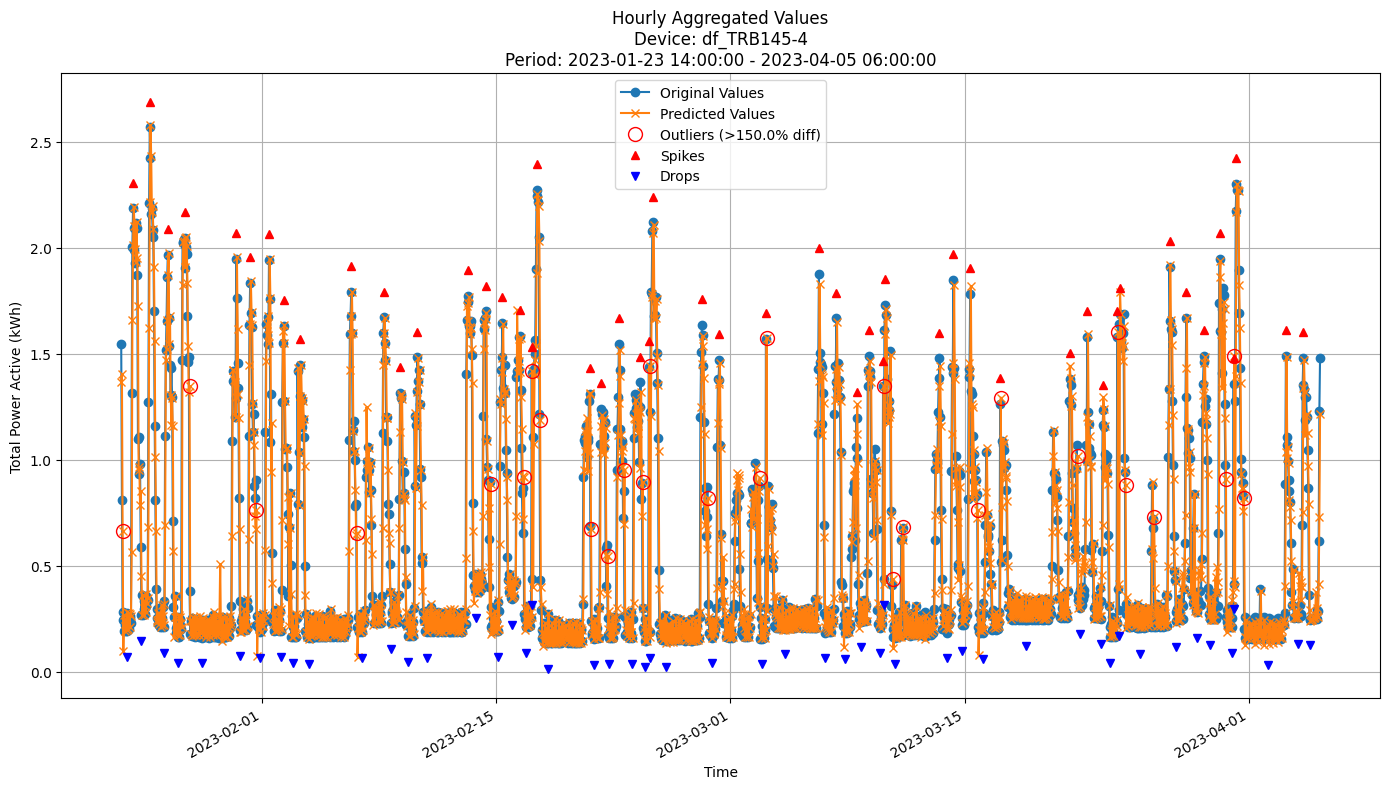


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2215
MAE: 0.1312
MAPE: 30.6118%

Directional Metrics:
Directional Accuracy: 37.0349%
First-Diff Correlation: 0.0948

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0588
  Recall: 0.0588
  F1 Score: 0.0588
Drops:
  Precision: 0.0196
  Recall: 0.0192
  F1 Score: 0.0194

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9608
  Recall: 0.9608
  F1 Score: 0.9608
Drops:
  Precision: 0.5098
  Recall: 0.5000
  F1 Score: 0.5049


In [54]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [55]:
# Define model classes and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, xfodt, arf, incb]
models_params = [
    bl_prev_params,
    bl_mean_params,
    gbdt_params,
    rf_params,
    hoef_params,
    arf_hf_params,
    fodt_params,
    xfodt_params,
    arf_params,
    incb_params,
 ]

model_test_results = {}
for model_class, params in zip(models_classes, models_params):
    if model_class in [gbdt, rf, bl_mean]:
        incremental = False
        update_freq = "14D"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")
    else:
        incremental = True
        update_freq = "1h"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model_class,
        model_params=params,
        train=train,
        valid=valid,
        test=test,
        use_residuals=USE_RESIDUAL,
        incremental=incremental,
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=ALL_FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=True
    )
    model_test_results[model_class.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-04-05 06:00:00
Model's memory usage: 0.000320 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-15 14:00:00 - 2023-05-30 17:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2103
	MAE: 0.0957
	MAPE: 16.6545%

Directional Metrics:
	Directional Accuracy: 49.0305%
	First-Diff Correlation: 0.1893

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.9744
		Recall: 1.0000
		F1: 0.9870
--------------------------------------------------
Daily Metrics:
----

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 13:00:00 to 2023-04-05 06:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-04-15 14:00:00 to 2023-04-29 14:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-04-29 14:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-04-29 15:00:00 to 2023-05-13 15:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-05-13 15:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-05-13 16:00:00 to 2023-05-27 16:00:00

-------------------------

Retraining model on data from 2022-09-20 13:00:00 to 2023-05-27 16:00:00

Time: 0.01 seconds
Predicting for chunk from 2023-05-27 17:00:00 to 2023-05-30 17:00:00

-------------------------
Model's memory usage: 0.024048 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-15 14:00:00 - 2023-05-30 17:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basi

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-04-05 06:00:00
Model's memory usage: 1369.934708 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-15 14:00:00 - 2023-05-30 17:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2378
	MAE: 0.1402
	MAPE: 33.4668%

Directional Metrics:
	Directional Accuracy: 56.3250%
	First-Diff Correlation: 0.3184

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2759
		Recall: 0.2051
		F1: 0.2353
	Drops:
		Precision: 0.0345
		Recall: 0.0263
		F1: 0.0299

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7241
		Recall: 0.5385
		F1: 0.6176
	Drops:
		Precision: 0.1724
		Recall: 0.1316
		F1: 0.1493
--------------------------------------------------
Daily Metrics:
-

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 41
Filtered feature count: 41
Excluded lag features: None
Initial training on data from 2022-09-20 13:00:00 to 2023-04-05 06:00:00
Model's memory usage: 0.829887 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-15 14:00:00 - 2023-05-30 17:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1910
	MAE: 0.0873
	MAPE: 15.8273%

Directional Metrics:
	Directional Accuracy: 48.5688%
	First-Diff Correlation: 0.2160

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.2051
		F1: 0.2025
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9750
		Recall: 1.0000
		F1: 0.9873
	Drops:
		Precision: 0.4750
		Recall: 0.5000
		F1: 0.4872
--------------------------------------------------
Daily Metrics:
----

In [56]:
for model_class in models_classes:
    model_test_results[model_class.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model_class.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [57]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [58]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "xFastODT": model_test_results[xfodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

In [59]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [60]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)



============================Hourly Test Results============================


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.210 ± 0.000,0.096 ± 0.000,16.655 ± 0.000,49.030 ± 0.000,18.929 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,98.701 ± 0.000
1,BL_Mean,0.196 ± 0.000,0.101 ± 0.000,22.726 ± 0.000,55.586 ± 0.000,30.015 ± 0.000,40.000 ± 0.000,82.500 ± 0.000,2.532 ± 0.000,27.848 ± 0.000
2,GBDT,0.183 ± 0.000,0.094 ± 0.000,19.688 ± 0.000,46.353 ± 0.000,25.884 ± 0.000,32.000 ± 0.000,93.333 ± 0.000,0.000 ± 0.000,24.324 ± 0.000
3,RandomForest,0.175 ± 0.000,0.086 ± 0.000,17.177 ± 0.000,47.461 ± 0.000,26.805 ± 0.000,26.316 ± 0.000,97.368 ± 0.000,2.667 ± 0.000,40.000 ± 0.000
4,HoeffdingTree,0.204 ± 0.000,0.106 ± 0.000,22.287 ± 0.000,49.861 ± 0.000,20.583 ± 0.000,29.333 ± 0.000,88.000 ± 0.000,8.108 ± 0.000,24.324 ± 0.000
5,ARF_Hoeffding,0.191 ± 0.000,0.089 ± 0.000,16.856 ± 0.000,49.307 ± 0.000,21.328 ± 0.000,5.195 ± 0.000,98.701 ± 0.000,2.632 ± 0.000,23.684 ± 0.000
6,FastODT,0.217 ± 0.000,0.106 ± 0.000,22.071 ± 0.000,48.661 ± 0.000,22.555 ± 0.000,26.190 ± 0.000,88.095 ± 0.000,4.819 ± 0.000,31.325 ± 0.000
7,xFastODT,0.209 ± 0.000,0.104 ± 0.000,22.326 ± 0.000,50.970 ± 0.000,24.725 ± 0.000,20.513 ± 0.000,71.795 ± 0.000,2.597 ± 0.000,23.377 ± 0.000
8,ARF_FastODT,0.238 ± 0.000,0.140 ± 0.000,33.467 ± 0.000,56.325 ± 0.000,31.836 ± 0.000,23.529 ± 0.000,61.765 ± 0.000,2.985 ± 0.000,14.925 ± 0.000
9,IncubationBoost,0.191 ± 0.000,0.087 ± 0.000,15.827 ± 0.000,48.569 ± 0.000,21.598 ± 0.000,20.253 ± 0.000,98.734 ± 0.000,0.000 ± 0.000,48.718 ± 0.000


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>BL_Prev</td>
      <td>0.208 ± 0.000</td>
      <td>0.096 ± 0.000</td>
      <td>16.450 ± 0.000</td>
      <td>48.847 ± 0.000</td>
      <td>18.428 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>100.000 ± 0.000</td>
    </tr>
    <tr>
      <th>1</th>
      <td>BL_Mean</td>
      <td>0.190 ± 0.000</td>
      <td>0.099 ± 0.000</td>
      <td>22.004 ± 0.000</td>
      <td>55.766 ± 0.000</td>
      <td>29.958 ± 0.000</td>
      <td>38.202 ± 0.000</td>
      <td>80.899 ± 0.000</td>
      <td>4.545 ± 0.000</td>
      <td>29.545 ± 0.000</td>
    </tr>
    <tr>
      <th>2</th>
      <td>GBDT</td>
      <td>0.173 ± 0.000</td>
      <td>0.089 ± 0.000</td>
      <td>17.972 ± 0.000</td>
      <td>48.764 ± 0.000</td>
      <td>29.129 ± 0.000</td>
      <td>26.190 ± 0.000</td>
      <td>90.476 ± 0.000</td>
      <td>4.878 ± 0.000</td>
      <td>29.268 ± 0.000</td>
    </tr>
    <tr>
      <th>3</th>
      <td>RandomForest</td>
      <td>0.167 ± 0.000</td>
      <td>0.082 ± 0.000</td>
      <td>15.932 ± 0.000</td>
      <td>51.318 ± 0.000</td>
      <td>28.014 ± 0.000</td>
      <td>27.273 ± 0.000</td>
      <td>97.727 ± 0.000</td>
      <td>4.651 ± 0.000</td>
      <td>30.233 ± 0.000</td>
    </tr>
    <tr>
      <th>4</th>
      <td>HoeffdingTree</td>
      <td>0.198 ± 0.000</td>
      <td>0.106 ± 0.000</td>
      <td>21.456 ± 0.000</td>
      <td>51.647 ± 0.000</td>
      <td>21.496 ± 0.000</td>
      <td>18.824 ± 0.000</td>
      <td>80.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>36.145 ± 0.000</td>
    </tr>
    <tr>
      <th>5</th>
      <td>ARF_Hoeffding</td>
      <td>0.186 ± 0.000</td>
      <td>0.088 ± 0.000</td>
      <td>16.294 ± 0.000</td>
      <td>50.494 ± 0.000</td>
      <td>21.899 ± 0.000</td>
      <td>11.364 ± 0.000</td>
      <td>95.455 ± 0.000</td>
      <td>6.977 ± 0.000</td>
      <td>37.209 ± 0.000</td>
    </tr>
    <tr>
      <th>6</th>
      <td>FastODT</td>
      <td>0.212 ± 0.000</td>
      <td>0.110 ± 0.000</td>
      <td>22.189 ± 0.000</td>
      <td>49.835 ± 0.000</td>
      <td>18.696 ± 0.000</td>
      <td>22.917 ± 0.000</td>
      <td>85.417 ± 0.000</td>
      <td>4.255 ± 0.000</td>
      <td>36.170 ± 0.000</td>
    </tr>
    <tr>
      <th>7</th>
      <td>ARF_FastODT</td>
      <td>0.205 ± 0.000</td>
      <td>0.102 ± 0.000</td>
      <td>21.087 ± 0.000</td>
      <td>56.755 ± 0.000</td>
      <td>26.959 ± 0.000</td>
      <td>27.957 ± 0.000</td>
      <td>79.570 ± 0.000</td>
      <td>10.753 ± 0.000</td>
      <td>30.108 ± 0.000</td>
    </tr>
    <tr>
      <th>8</th>
      <td>IncubationBoost</td>
      <td>0.188 ± 0.000</td>
      <td>0.088 ± 0.000</td>
      <td>16.070 ± 0.000</td>
      <td>48.847 ± 0.000</td>
      <td>23.186 ± 0.000</td>
      <td>10.989 ± 0.000</td>
      <td>98.901 ± 0.000</td>
      <td>6.742 ± 0.000</td>
      <td>47.191 ± 0.000</td>
    </tr>
  </tbody>
</table>
</div>

## Validation results

In [61]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "xFastODT": xfodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)



============================Hourly Validation Results============================


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.255 ± 0.012,0.146 ± 0.004,28.289 ± 5.795,35.807 ± 1.544,8.082 ± 14.124,0.000 ± 0.000,83.333 ± 37.268,0.000 ± 0.000,83.333 ± 37.268
1,BL_Mean,0.216 ± 0.027,0.136 ± 0.012,29.336 ± 5.120,40.641 ± 2.752,17.985 ± 14.596,8.742 ± 11.529,64.180 ± 31.434,3.242 ± 3.259,25.604 ± 16.606
2,GBDT,0.225 ± 0.027,0.140 ± 0.023,29.381 ± 2.982,41.048 ± 2.971,20.697 ± 14.465,8.407 ± 11.549,50.628 ± 28.414,3.110 ± 4.618,16.840 ± 13.582
3,RandomForest,0.116 ± 0.012,0.075 ± 0.008,14.869 ± 2.033,44.927 ± 6.811,69.150 ± 5.226,11.765 ± 18.988,38.157 ± 39.956,2.609 ± 3.711,5.699 ± 8.439
4,HoeffdingTree,0.243 ± 0.016,0.149 ± 0.008,31.551 ± 6.977,40.493 ± 2.634,12.713 ± 13.798,14.801 ± 12.605,64.305 ± 30.495,1.190 ± 2.662,22.895 ± 12.212
5,ARF_Hoeffding,0.227 ± 0.017,0.133 ± 0.008,26.645 ± 4.800,37.234 ± 2.689,12.486 ± 14.652,7.295 ± 6.452,70.447 ± 32.312,0.000 ± 0.000,36.715 ± 17.445
6,FastODT,0.245 ± 0.011,0.147 ± 0.005,30.670 ± 7.678,36.185 ± 1.729,10.089 ± 15.960,2.262 ± 3.242,76.665 ± 35.625,2.130 ± 3.026,46.321 ± 31.458
7,xFastODT,0.223 ± 0.032,0.140 ± 0.016,31.191 ± 7.428,39.038 ± 3.469,20.811 ± 15.114,6.429 ± 6.277,68.156 ± 32.713,4.223 ± 3.012,35.399 ± 30.824
8,ARF_FastODT,0.277 ± 0.022,0.171 ± 0.011,37.123 ± 8.666,47.132 ± 2.206,9.335 ± 10.480,9.987 ± 7.800,50.092 ± 24.407,4.147 ± 4.496,15.193 ± 8.016
9,IncubationBoost,0.235 ± 0.022,0.137 ± 0.010,27.907 ± 6.101,36.505 ± 2.109,11.950 ± 17.176,3.341 ± 5.009,79.457 ± 35.679,2.302 ± 3.258,45.952 ± 26.009


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>BL_Prev</td>
      <td>0.227 ± 0.042</td>
      <td>0.128 ± 0.031</td>
      <td>23.862 ± 7.597</td>
      <td>39.183 ± 4.839</td>
      <td>18.652 ± 19.926</td>
      <td>0.000 ± 0.000</td>
      <td>85.714 ± 34.993</td>
      <td>0.000 ± 0.000</td>
      <td>85.253 ± 34.822</td>
    </tr>
    <tr>
      <th>1</th>
      <td>BL_Mean</td>
      <td>0.189 ± 0.041</td>
      <td>0.117 ± 0.029</td>
      <td>25.727 ± 5.448</td>
      <td>45.743 ± 8.879</td>
      <td>28.821 ± 19.767</td>
      <td>20.717 ± 16.118</td>
      <td>63.929 ± 30.776</td>
      <td>3.378 ± 4.113</td>
      <td>28.702 ± 25.055</td>
    </tr>
    <tr>
      <th>2</th>
      <td>GBDT</td>
      <td>0.201 ± 0.040</td>
      <td>0.119 ± 0.036</td>
      <td>24.945 ± 5.082</td>
      <td>43.505 ± 6.421</td>
      <td>27.555 ± 15.964</td>
      <td>11.530 ± 12.847</td>
      <td>57.061 ± 38.309</td>
      <td>0.733 ± 1.794</td>
      <td>21.455 ± 14.867</td>
    </tr>
    <tr>
      <th>3</th>
      <td>RandomForest</td>
      <td>0.117 ± 0.010</td>
      <td>0.069 ± 0.007</td>
      <td>13.657 ± 1.793</td>
      <td>48.332 ± 6.259</td>
      <td>65.099 ± 5.727</td>
      <td>12.706 ± 15.608</td>
      <td>43.963 ± 39.491</td>
      <td>6.683 ± 7.236</td>
      <td>11.346 ± 11.115</td>
    </tr>
    <tr>
      <th>4</th>
      <td>HoeffdingTree</td>
      <td>0.211 ± 0.042</td>
      <td>0.129 ± 0.027</td>
      <td>27.697 ± 6.308</td>
      <td>42.207 ± 4.036</td>
      <td>21.614 ± 18.275</td>
      <td>16.159 ± 14.655</td>
      <td>70.606 ± 31.123</td>
      <td>0.000 ± 0.000</td>
      <td>26.992 ± 13.409</td>
    </tr>
    <tr>
      <th>5</th>
      <td>ARF_Hoeffding</td>
      <td>0.198 ± 0.044</td>
      <td>0.115 ± 0.030</td>
      <td>22.913 ± 6.622</td>
      <td>42.017 ± 6.802</td>
      <td>23.203 ± 21.768</td>
      <td>12.276 ± 11.083</td>
      <td>76.743 ± 32.211</td>
      <td>2.765 ± 6.773</td>
      <td>39.297 ± 20.148</td>
    </tr>
    <tr>
      <th>6</th>
      <td>FastODT</td>
      <td>0.225 ± 0.039</td>
      <td>0.132 ± 0.029</td>
      <td>26.782 ± 8.276</td>
      <td>43.252 ± 6.035</td>
      <td>20.534 ± 17.332</td>
      <td>9.012 ± 12.607</td>
      <td>65.916 ± 33.154</td>
      <td>1.704 ± 2.721</td>
      <td>28.086 ± 22.909</td>
    </tr>
    <tr>
      <th>7</th>
      <td>ARF_FastODT</td>
      <td>0.226 ± 0.039</td>
      <td>0.139 ± 0.026</td>
      <td>31.303 ± 7.977</td>
      <td>50.831 ± 5.322</td>
      <td>32.192 ± 12.723</td>
      <td>21.880 ± 15.440</td>
      <td>56.239 ± 25.923</td>
      <td>6.463 ± 9.844</td>
      <td>27.376 ± 16.032</td>
    </tr>
    <tr>
      <th>8</th>
      <td>IncubationBoost</td>
      <td>0.207 ± 0.043</td>
      <td>0.118 ± 0.032</td>
      <td>22.986 ± 7.411</td>
      <td>40.461 ± 4.427</td>
      <td>21.677 ± 19.850</td>
      <td>4.167 ± 6.682</td>
      <td>78.313 ± 32.205</td>
      <td>5.700 ± 7.946</td>
      <td>49.131 ± 28.542</td>
    </tr>
  </tbody>
</table>
</div>

### By-period validation results

In [62]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Mean": bl_prev_valid_period_metrics,
    "BL_Prev": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)


In [63]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,33.042,43.357,39.336,33.217,37.063,33.042,33.042,46.154,32.692,36.771667
Period 2,37.871,42.234,43.979,37.696,44.154,36.649,37.347,47.295,38.569,40.643778
Period 3,35.664,43.357,42.832,37.762,38.112,41.783,37.238,48.427,36.888,40.229222
Period 4,36.300,37.522,43.630,37.696,43.281,37.173,37.347,51.134,37.871,40.217111
Period 5,34.965,36.364,41.084,35.315,38.986,35.839,34.615,44.406,34.790,37.373778
Period 6,36.998,41.012,35.428,35.602,41.361,38.918,37.522,45.375,38.220,38.937333



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,4.829,-1.123,4.643,4.479,7.091,3.607,4.305,1.141,5.877,3.872
Period 3 - Period 2,-2.207,1.123,-1.147,0.066,-6.042,5.134,-0.109,1.132,-1.681,-0.415
Period 4 - Period 3,0.636,-5.835,0.798,-0.066,5.169,-4.610,0.109,2.707,0.983,-0.012
Period 5 - Period 4,-1.335,-1.158,-2.546,-2.381,-4.295,-1.334,-2.732,-6.728,-3.081,-2.843
Period 6 - Period 5,2.033,4.648,-5.656,0.287,2.375,3.079,2.907,0.969,3.430,1.564


#### MAPE (lower is better)

In [64]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | MAPE (%) per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,17.963,19.924,26.003,18.927,19.741,17.842,18.002,23.664,18.127,20.021444
Period 2,24.007,26.807,29.259,25.814,26.991,23.114,24.153,30.320,23.349,25.979333
Period 3,32.582,34.182,31.926,34.254,38.871,29.683,36.110,49.226,34.121,35.661667
Period 4,30.139,29.220,25.661,26.416,30.562,28.385,36.405,34.738,27.124,29.850000
Period 5,35.590,35.471,34.031,31.992,40.237,32.357,39.975,45.174,36.102,36.769889
Period 6,29.454,30.409,29.408,28.018,32.903,28.491,29.376,39.616,28.619,30.699333



Absolute gain/drop in MAPE (%):


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,6.044,6.883,3.256,6.887,7.250,5.272,6.151,6.656,5.222,5.958
Period 3 - Period 2,8.575,7.375,2.667,8.440,11.880,6.569,11.957,18.906,10.772,9.682
Period 4 - Period 3,-2.443,-4.962,-6.265,-7.838,-8.309,-1.298,0.295,-14.488,-6.997,-5.812
Period 5 - Period 4,5.451,6.251,8.370,5.576,9.675,3.972,3.570,10.436,8.978,6.920
Period 6 - Period 5,-6.136,-5.062,-4.623,-3.974,-7.334,-3.866,-10.599,-5.558,-7.483,-6.071


#### RMSE (lower is better)

In [65]:
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | RMSE per period


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.260,0.263,0.268,0.232,0.262,0.246,0.260,0.309,0.259,0.262111
Period 2,0.267,0.228,0.238,0.217,0.254,0.241,0.245,0.264,0.233,0.243000
Period 3,0.271,0.226,0.220,0.221,0.253,0.240,0.253,0.307,0.255,0.249556
Period 4,0.246,0.179,0.184,0.182,0.217,0.201,0.235,0.265,0.195,0.211556
Period 5,0.251,0.192,0.237,0.214,0.249,0.222,0.248,0.263,0.248,0.236000
Period 6,0.237,0.209,0.204,0.200,0.224,0.211,0.228,0.253,0.218,0.220444



Absolute gain/drop in RMSE:


,BL_Mean,BL_Prev,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.007,-0.035,-0.030,-0.015,-0.008,-0.005,-0.015,-0.045,-0.026,-0.019
Period 3 - Period 2,0.004,-0.002,-0.018,0.004,-0.001,-0.001,0.008,0.043,0.022,0.007
Period 4 - Period 3,-0.025,-0.047,-0.036,-0.039,-0.036,-0.039,-0.018,-0.042,-0.060,-0.038
Period 5 - Period 4,0.005,0.013,0.053,0.032,0.032,0.021,0.013,-0.002,0.053,0.024
Period 6 - Period 5,-0.014,0.017,-0.033,-0.014,-0.025,-0.011,-0.020,-0.010,-0.030,-0.016
